# Prediksi Harga Mobil Ford Bekas

Notebook ini menyelesaikan soal regresi pada berkas `ford.csv` dengan alur *CRISP-DM*. Tujuannya memperkirakan harga listing mobil Ford bekas dari spesifikasi yang sudah tertera di iklan.

Jika notebook dibuka di komputer dan `ford.csv` berada di folder yang sama, berkas itu langsung terbaca.

## Hasil yang perlu diingat

*Target* yang dipakai adalah kolom `price`, yaitu harga listing dalam pound sterling.

Model yang dipilih adalah *HistGradientBoosting* dengan set fitur *lean* setelah *tuning*. Pemilihan memakai *RMSE* *cross-validation* 5-*fold* pada data latih, yaitu **£1.185**. Data uji tidak ikut memilih model.

Pada 3.562 mobil uji, dengan *random state* 42:

| Metrik | Nilai |
| --- | ---: |
| *R²* | 0,944 |
| *RMSE* | £1.121 |
| *MAE* | £805 |
| Galat absolut median | £604 |
| *MAPE* | 7,06% |
| Prediksi dalam 5% harga aktual | 46,4% |
| Prediksi dalam 10% harga aktual | 78,6% |
| Prediksi dalam 15% harga aktual | 92,1% |

Regresi tidak punya *accuracy* seperti klasifikasi. Sebagai padanan yang mudah dibaca, **prediksi dalam 10%** adalah persentase mobil yang harga tebakannya menyimpang paling banyak 10% dari harga aktual. Tebakan “semua mobil seharga median” hanya mencapai 20,9% pada tolok ukur itu. Model akhir mencapai 78,6%.


## 1. Pemahaman bisnis

Dataset ini berisi listing mobil Ford bekas: model, tahun registrasi, harga, transmisi, jarak tempuh, bahan bakar, pajak, konsumsi `mpg`, dan kapasitas mesin. Pertanyaan yang ingin dijawab:

> Berapa harga pasar yang wajar untuk sebuah Ford bekas, jika spesifikasi dan pemakaiannya sudah diketahui?

Jawaban itu berguna bagi penjual yang memasang harga, pembeli yang ingin melihat listing terlalu mahal atau terlalu murah, dan dealer yang perlu menaksir stok tanpa menilai setiap mobil secara manual.

### Kriteria berhasil

- Model mengalahkan *baseline*: semua mobil ditebak seharga median data latih.
- *R²* pada data yang tidak ikut pelatihan berada di atas 0,90.
- *MAE* berada di bawah 10% median harga. Median harga setelah pembersihan sekitar £11.288, jadi batas kasarnya £1.100.

### Mengapa `price` yang menjadi *target*

`price` adalah besaran kontinu dan merupakan hasil pasar. Atribut lain sudah tertera di iklan sebelum harga dipasang, lalu bersama-sama menjelaskan harga tersebut.

| Kolom | Peran dalam soal ini |
| --- | --- |
| `price` | *Target*. Harga yang ingin ditaksir. |
| `model`, `transmission`, `fuelType` | Identitas mobil. |
| `year`, `mileage` | Usia dan pemakaian. |
| `engineSize`, `mpg`, `tax` | Spesifikasi teknis dan pajak. |

Korelasi harga dengan tahun sekitar +0,65 dan dengan jarak tempuh sekitar −0,53. Sinyal itu cukup kuat untuk regresi. Memprediksi tahun, jarak, atau `mpg` tidak menjawab kebutuhan penetapan harga, karena ketiga hal itu sudah diketahui saat iklan dibuat.


In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import (
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.exceptions import ConvergenceWarning
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

try:
    from xgboost import XGBRegressor
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost"])
    from xgboost import XGBRegressor

try:
    from sklearn.metrics import root_mean_squared_error
except ImportError:
    def root_mean_squared_error(y_true, y_pred):
        return float(mean_squared_error(y_true, y_pred) ** 0.5)

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 30)

def format_angka(nilai):
    if abs(nilai) < 2:
        return f"{nilai:.4f}"
    if abs(nilai) < 100:
        return f"{nilai:.2f}"
    return f"{nilai:,.2f}"

pd.set_option("display.float_format", format_angka)

RANDOM_STATE = 42
REF_YEAR = 2020
RARE_MIN = 15

RAW_NUM = ["year", "mileage", "tax", "mpg", "engineSize"]
RAW_CAT = ["model_grouped", "transmission", "fuel_grouped"]
FE_NUM = [
    "vehicle_age", "age_sq", "mileage", "log_mileage", "miles_per_year",
    "tax", "mpg", "engineSize", "efficiency", "engine_missing",
]
FE_CAT = ["model_grouped", "transmission", "fuel_grouped"]
LEAN_NUM = ["year", "mileage", "miles_per_year", "tax", "mpg", "engineSize", "engine_missing"]
LEAN_CAT = ["model_grouped", "transmission", "fuel_grouped"]

print("Pustaka siap. Seed =", RANDOM_STATE)


Pustaka siap. Seed = 42


## 2. Pemahaman Data Awal (* Initial Exploratory Data Analysis*)

Tahap ini mengenali bentuk data sebelum model dilatih: jumlah baris, nilai yang hilang, sebaran harga, dan hubungan antar kolom.

In [3]:
def cari_berkas_data():
    kandidat = [
        Path("ford.csv"),
        Path("/content/ford.csv"),
        Path("/content/drive/MyDrive/ford.csv"),
    ]
    for jalur in kandidat:
        if jalur.exists():
            print("Berkas data:", jalur.resolve())
            return jalur
    try:
        from google.colab import files
        print("ford.csv belum ada di folder kerja. Pilih berkas tersebut pada jendela unggah.")
        files.upload()
    except ImportError:
        pass
    if Path("ford.csv").exists():
        print("Berkas data: ford.csv")
        return Path("ford.csv")
    raise FileNotFoundError(
        "ford.csv tidak ditemukan. Unggah berkas itu ke folder kerja, lalu jalankan sel ini lagi."
    )

mentah = pd.read_csv(cari_berkas_data())
mentah.columns = [kolom.strip() for kolom in mentah.columns]
print("Ukuran mentah:", mentah.shape)
print("\nTipe data:")
print(mentah.dtypes)
print("\nJumlah nilai kosong:")
print(mentah.isna().sum())
print("\nJumlah baris duplikat:", int(mentah.duplicated().sum()))
print("\nContoh nama model sebelum dibersihkan:", repr(mentah["model"].head(3).tolist()))


ford.csv belum ada di folder kerja. Pilih berkas tersebut pada jendela unggah.


Saving ford.csv to ford.csv
Berkas data: ford.csv
Ukuran mentah: (17966, 9)

Tipe data:
model            object
year              int64
price             int64
transmission     object
mileage           int64
fuelType         object
tax               int64
mpg             float64
engineSize      float64
dtype: object

Jumlah nilai kosong:
model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
dtype: int64

Jumlah baris duplikat: 154

Contoh nama model sebelum dibersihkan: [' Fiesta', ' Focus', ' Focus']


In [5]:
ikhtisar = mentah.copy()
ikhtisar["model"] = ikhtisar["model"].astype(str).str.strip()

print("Jumlah model sebelum spasi dibuang:", mentah["model"].nunique())
print("Jumlah model sesudah spasi dibuang:", ikhtisar["model"].nunique())
print("\nStatistik numerik:")
display(ikhtisar.describe().T)
print("\nJumlah mobil per model:")
display(ikhtisar["model"].value_counts().rename("jumlah").to_frame())
print("\nTransmisi:")
display(ikhtisar["transmission"].value_counts().rename("jumlah").to_frame())
print("\nBahan bakar:")
display(ikhtisar["fuelType"].value_counts().rename("jumlah").to_frame())


Jumlah model sebelum spasi dibuang: 24
Jumlah model sesudah spasi dibuang: 23

Statistik numerik:


,count,mean,std,min,25%,50%,75%,max
year,"17,966.00","2,016.87",2.05,"1,996.00","2,016.00","2,017.00","2,018.00","2,060.00"
price,"17,966.00","12,279.53","4,741.34",495.00,"8,999.00","11,291.00","15,299.00","54,995.00"
mileage,"17,966.00","23,362.61","19,472.05",1.0000,"9,987.00","18,242.50","31,060.00","177,644.00"
tax,"17,966.00",113.33,62.01,0.0000,30.00,145.00,145.00,580.00
mpg,"17,966.00",57.91,10.13,20.80,52.30,58.90,65.70,201.80
engineSize,"17,966.00",1.3508,0.4324,0.0000,1.0000,1.2000,1.5000,5.00



Jumlah mobil per model:


,jumlah
model,
Fiesta,6557
Focus,4589
Kuga,2225
EcoSport,1143
C-MAX,543
Ka+,531
Mondeo,526
B-MAX,355
S-MAX,296



Transmisi:


,jumlah
transmission,
Manual,15518
Automatic,1361
Semi-Auto,1087



Bahan bakar:


,jumlah
fuelType,
Petrol,12179
Diesel,5762
Hybrid,22
Electric,2
Other,1


In [6]:
angka = ["price", "year", "mileage", "tax", "mpg", "engineSize"]
print("Nilai ekstrem")
for kolom in angka:
    seri = ikhtisar[kolom]
    print(
        f"{kolom:12} min={seri.min():>10}  median={seri.median():>10.1f}  "
        f"maks={seri.max():>10}"
    )

print("\nMesin bernilai 0:", int((ikhtisar["engineSize"] == 0).sum()))
print("Pajak bernilai 0:", int((ikhtisar["tax"] == 0).sum()))
print("Kemiringan harga (skewness):", round(float(ikhtisar["price"].skew()), 3))

print("\nBaris dengan tahun di luar kewajaran:")
display(ikhtisar.loc[ikhtisar["year"] > 2020, ["model", "year", "price", "mileage", "transmission", "engineSize"]])
print("Harga tertinggi:")
display(ikhtisar.nlargest(5, "price")[["model", "year", "price", "mileage", "transmission", "engineSize"]])


Nilai ekstrem
price        min=       495  median=   11291.0  maks=     54995
year         min=      1996  median=    2017.0  maks=      2060
mileage      min=         1  median=   18242.5  maks=    177644
tax          min=         0  median=     145.0  maks=       580
mpg          min=      20.8  median=      58.9  maks=     201.8
engineSize   min=       0.0  median=       1.2  maks=       5.0

Mesin bernilai 0: 51
Pajak bernilai 0: 2153
Kemiringan harga (skewness): 1.096

Baris dengan tahun di luar kewajaran:


,model,year,price,mileage,transmission,engineSize
17726,Fiesta,2060,6495,54807,Automatic,1.4000


Harga tertinggi:


,model,year,price,mileage,transmission,engineSize
11912,Focus,2018,54995,11000,Manual,2.30
11913,Mustang,2017,49999,21575,Manual,5.00
11910,Mustang,2017,48999,7546,Automatic,5.00
17866,Mustang,2020,48000,50,Manual,5.00
12613,Mustang,2019,45250,2500,Automatic,5.00


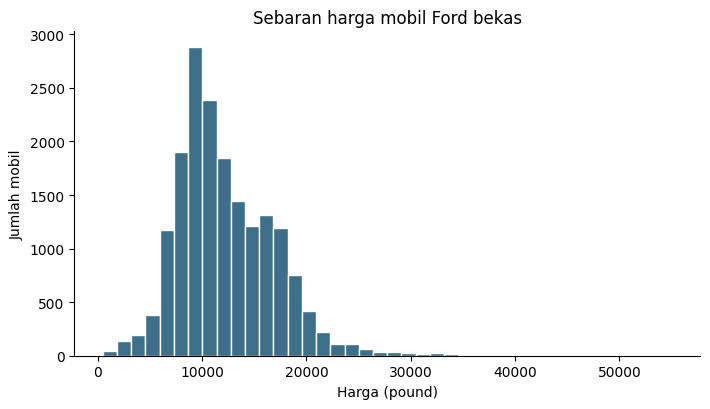

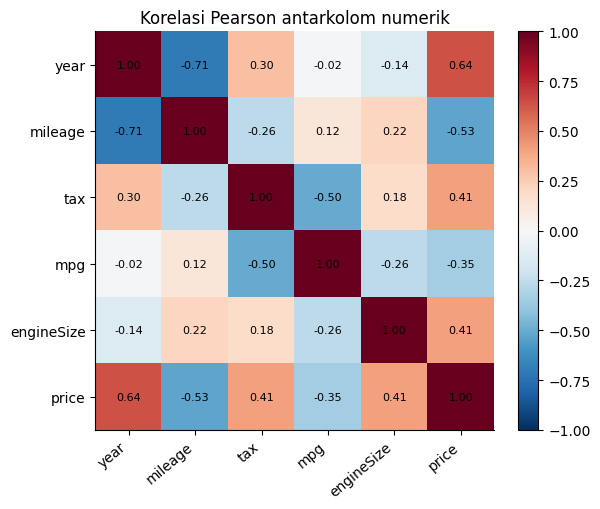

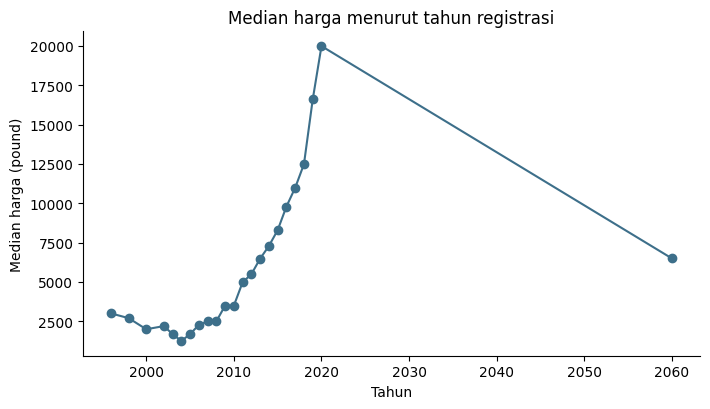

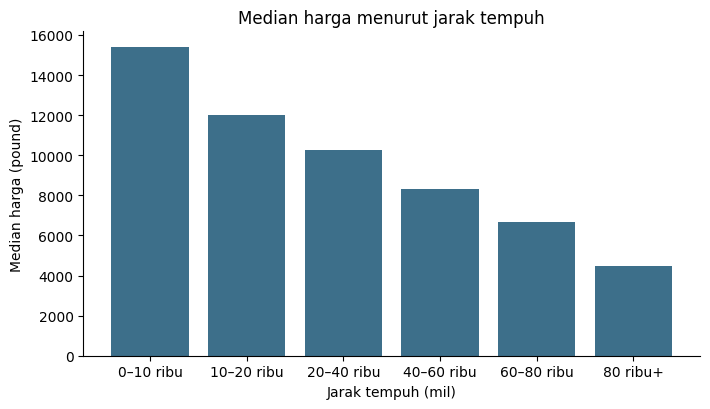

Korelasi dengan harga:


,korelasi_dengan_harga
year,0.6360
engineSize,0.4112
tax,0.4069
mpg,-0.3464
mileage,-0.5307


Median harga menurut transmisi:


,jumlah,median,rata_rata
transmission,,,
Automatic,1361,"15,698.00","15,727.20"
Manual,15518,"10,991.00","11,792.30"
Semi-Auto,1087,"13,689.00","14,919.00"


Median harga menurut bahan bakar:


,jumlah,median,rata_rata
fuelType,,,
Diesel,5762,"13,289.00","13,659.20"
Electric,2,"15,737.50","15,737.50"
Hybrid,22,"23,498.50","22,149.10"
Other,1,"13,800.00","13,800.00"
Petrol,12179,"10,800.00","11,608.30"


In [7]:
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.titlesize": 12,
})

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.hist(ikhtisar["price"], bins=40, color="#3d6f8a", edgecolor="white")
ax.set_title("Sebaran harga mobil Ford bekas")
ax.set_xlabel("Harga (pound)")
ax.set_ylabel("Jumlah mobil")
fig.tight_layout()
plt.show()

kolom_korelasi = ["year", "mileage", "tax", "mpg", "engineSize", "price"]
korelasi = ikhtisar[kolom_korelasi].corr()
fig, ax = plt.subplots(figsize=(6.2, 5.2))
gambar = ax.imshow(korelasi.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(kolom_korelasi)), kolom_korelasi, rotation=40, ha="right")
ax.set_yticks(range(len(kolom_korelasi)), kolom_korelasi)
for i in range(len(kolom_korelasi)):
    for j in range(len(kolom_korelasi)):
        ax.text(j, i, f"{korelasi.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Korelasi Pearson antarkolom numerik")
fig.colorbar(gambar, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

harga_tahun = ikhtisar.groupby("year")["price"].median()
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(harga_tahun.index, harga_tahun.values, marker="o", color="#3d6f8a")
ax.set_title("Median harga menurut tahun registrasi")
ax.set_xlabel("Tahun")
ax.set_ylabel("Median harga (pound)")
fig.tight_layout()
plt.show()

kelompok_jarak = pd.cut(
    ikhtisar["mileage"],
    bins=[0, 10000, 20000, 40000, 60000, 80000, 200000],
    labels=["0–10 ribu", "10–20 ribu", "20–40 ribu", "40–60 ribu", "60–80 ribu", "80 ribu+"],
)
median_jarak = ikhtisar.groupby(kelompok_jarak, observed=True)["price"].median()
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.bar(median_jarak.index.astype(str), median_jarak.values, color="#3d6f8a")
ax.set_title("Median harga menurut jarak tempuh")
ax.set_xlabel("Jarak tempuh (mil)")
ax.set_ylabel("Median harga (pound)")
fig.tight_layout()
plt.show()

print("Korelasi dengan harga:")
display(korelasi["price"].drop("price").sort_values(ascending=False).rename("korelasi_dengan_harga").to_frame())
print("Median harga menurut transmisi:")
display(ikhtisar.groupby("transmission")["price"].agg(jumlah="size", median="median", rata_rata="mean").round(1))
print("Median harga menurut bahan bakar:")
display(ikhtisar.groupby("fuelType")["price"].agg(jumlah="size", median="median", rata_rata="mean").round(1))


### Bacaan dari eksplorasi

Data mentah berisi **17.966 baris dan 9 kolom**. Tidak ada *missing value* yang tertulis sebagai sel kosong. Yang ada adalah nilai yang secara makna tidak masuk akal, dan itu baru ketahuan setelah sebarannya dilihat.

Nama model menyimpan spasi di depan, misalnya `" Fiesta"`. Sebelum spasi dibuang tampak ada 24 label. Sesudahnya ada **23 model**. Fiesta, Focus, dan Kuga mendominasi jumlah listing. Mustang sedikit, tetapi median harganya jauh di atas Fiesta.

Harga miring ke kanan (*skewness* sekitar 1,07). Mean berada di atas median. Karena ekor kanan itu, model garis lurus lebih stabil jika harga terlebih dahulu diubah ke skala *log*.

Pola yang konsisten dengan pasar mobil bekas:

- Makin baru tahun registrasinya, makin tinggi median harganya. Dari sekitar £6.500 pada tahun 2013 hingga sekitar £20.000 pada tahun 2020.
- Makin jauh jarak tempuhnya, makin rendah median harganya. Di bawah 10.000 mil mediannya sekitar £15.400. Di atas 80.000 mil mediannya sekitar £4.500.
- Transmisi otomatis lebih mahal daripada manual. Diesel lebih mahal daripada bensin. Hybrid hanya puluhan baris, tetapi median harganya di atas £23.000.

Tahun dan jarak tempuh berkorelasi sekitar **−0,72**. Mobil baru biasanya belum jauh dipakai. Korelasi itu nyata, tetapi *Variance Inflation Factor* semua kolom numerik nanti berada di bawah 2,3, jadi kolinearitasnya belum merusak model linear.

Temuan kualitas yang menentukan langkah pembersihan:

1. Ada **154 baris duplikat**.
2. Satu Fiesta bertahun **2060**, harga £6.495, jarak 54.807 mil. Tahun itu tidak mungkin. Polanya cocok dengan data yang salah ketik, bukan mobil dari masa depan.
3. Satu Focus 2018 bertransmisi manual, mesin 2,3 liter, berharga **£54.995**. Focus termahal berikutnya berada di sekitar £38.000. Harga £54.995 berada di wilayah harga Mustang.
4. `engineSize = 0` muncul pada puluhan baris. Kapasitas mesin nol liter tidak masuk akal. Ini penanda ukuran mesin yang tidak tercatat.
5. Pajak £0 muncul pada lebih dari dua ribu baris. Pada listing di Inggris, pajak nol dapat sah untuk mobil emisi rendah, jadi baris itu **dipertahankan**.
6. `mpg` sebesar 201,8 pada Kuga Hybrid tahun 2020 adalah angka efisiensi *plug-in hybrid*, bukan salah ketik. Baris itu dipertahankan.


## 3. Persiapan data (*preprocessing*)

Pembersihan memakai aturan domain, lalu data dibagi menjadi data latih dan data uji. Statistik yang dipelajari dari data, seperti median mesin per model, baru dihitung di dalam *pipeline* pada data latih. Dengan begitu informasi data uji tidak bocor ke model.

Aturan yang diterapkan pada seluruh data sebelum pembagian:

- Buang spasi pada nama model.
- Hapus baris duplikat.
- Hapus tahun di atas 2020. Pada berkas ini, itu adalah Fiesta tahun 2060.
- Hapus harga di atas £45.000 pada mobil yang bukan Mustang. Pada berkas ini, itu adalah Focus seharga £54.995.

Yang sengaja tidak dihapus: mobil tua yang murah, pajak nol, dan mesin bernilai 0. Mesin nol akan diisi nanti, bukan dibuang, karena harga dan `mpg` pada baris itu tetap masuk akal.

Pembagian data: **80% latih dan 20% uji**, dengan `random_state=42`.


In [8]:
def bersihkan(data_mentah):
    laporan = {
        "baris_mentah": int(len(data_mentah)),
        "nilai_kosong": {kolom: int(data_mentah[kolom].isna().sum()) for kolom in data_mentah.columns},
    }
    data = data_mentah.copy()
    data["model"] = data["model"].astype(str).str.strip()
    sebelum = len(data)
    data = data.drop_duplicates()
    laporan["duplikat_dihapus"] = int(sebelum - len(data))

    tahun_rusak = data["year"] > REF_YEAR
    laporan["tahun_mustahil"] = data.loc[
        tahun_rusak, ["model", "year", "price", "mileage", "transmission"]
    ]
    data = data.loc[~tahun_rusak].copy()

    harga_mustahil = (data["model"] != "Mustang") & (data["price"] > 45000)
    laporan["harga_mustahil"] = data.loc[
        harga_mustahil, ["model", "year", "price", "mileage", "transmission", "engineSize"]
    ]
    data = data.loc[~harga_mustahil].copy()

    laporan["mesin_nol"] = int((data["engineSize"] <= 0).sum())
    laporan["pajak_nol"] = int((data["tax"] == 0).sum())
    laporan["baris_bersih"] = int(len(data))
    laporan["skewness_harga"] = float(data["price"].skew())
    return data.reset_index(drop=True), laporan

data, laporan_bersih = bersihkan(mentah)
print("Baris mentah        :", laporan_bersih["baris_mentah"])
print("Duplikat dihapus    :", laporan_bersih["duplikat_dihapus"])
print("Baris bersih        :", laporan_bersih["baris_bersih"])
print("Mesin bernilai 0    :", laporan_bersih["mesin_nol"], "(dipertahankan, akan diisi)")
print("Pajak bernilai 0    :", laporan_bersih["pajak_nol"], "(dipertahankan)")
print("Skewness harga      :", round(laporan_bersih["skewness_harga"], 3))
print("\nBaris tahun yang dihapus:")
display(laporan_bersih["tahun_mustahil"])
print("Baris harga yang dihapus:")
display(laporan_bersih["harga_mustahil"])
print("\nRingkasan data bersih:")
display(data[["price", "year", "mileage", "tax", "mpg", "engineSize"]].describe().T)


Baris mentah        : 17966
Duplikat dihapus    : 154
Baris bersih        : 17810
Mesin bernilai 0    : 51 (dipertahankan, akan diisi)
Pajak bernilai 0    : 2137 (dipertahankan)
Skewness harga      : 1.065

Baris tahun yang dihapus:


,model,year,price,mileage,transmission
17726,Fiesta,2060,6495,54807,Automatic


Baris harga yang dihapus:


,model,year,price,mileage,transmission,engineSize
11912,Focus,2018,54995,11000,Manual,2.30



Ringkasan data bersih:


,count,mean,std,min,25%,50%,75%,max
price,"17,810.00","12,267.48","4,725.52",495.00,"8,999.00","11,288.00","15,295.00","49,999.00"
year,"17,810.00","2,016.86",2.03,"1,996.00","2,016.00","2,017.00","2,018.00","2,020.00"
mileage,"17,810.00","23,380.08","19,418.45",1.0000,"10,000.00","18,277.00","31,095.25","177,644.00"
tax,"17,810.00",113.31,62.03,0.0000,30.00,145.00,145.00,580.00
mpg,"17,810.00",57.91,10.13,20.80,52.30,58.90,65.70,201.80
engineSize,"17,810.00",1.3506,0.4325,0.0000,1.0000,1.2000,1.5000,5.00


### Bacaan dari pembersihan

Dari 17.966 baris, **154 duplikat**, **1 tahun mustahil**, dan **1 harga Focus yang tidak masuk akal** dikeluarkan. Sisa data bersih **17.810 baris**.

Dua baris yang dihapus itu bukan mobil langka yang ingin dipelajari. Keduanya memutus pola yang konsisten di sisa data. Mobil tua berharga beberapa ratus pound tetap ada, karena kombinasi tahun lama dan jarak jauh memang menghasilkan harga rendah.

Median harga pada data bersih sekitar **£11.288**. Angka ini menjadi patokan *baseline* dan patokan “10% dari harga tengah”.


## 4. Pemahaman data (*Exploratory Data Analysis*)

Tahap ini dilakukan analisa mengenai hubungan antar fitur dengan target sebelum dilakukan pemodelan.

### a. Does newer year mean higher price?

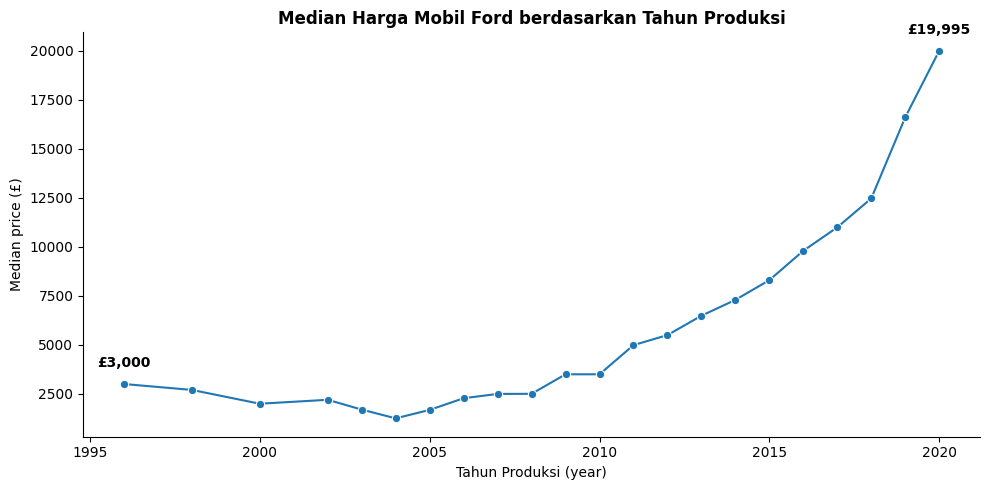

INSIGHT: MEDIAN HARGA MOBIL FORD BERDASARKAN TAHUN PRODUKSI
Periode data       : 1996–2020
Median harga awal  : £3,000
Median harga akhir : £19,995
Perubahan harga    : +566.5%
Perbandingan harga : 6.67x dari harga awal


In [9]:
year_price = (
    data.groupby('year')['price']
    .median()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.lineplot(
    data=year_price,
    x='year',
    y='price',
    marker='o',
    ax=ax
)

# Ambil data tahun pertama dan terakhir
first = year_price.iloc[0]
last = year_price.iloc[-1]

# Hitung perubahan harga
price_start = first['price']
price_end = last['price']

percent_change = ((price_end - price_start) / price_start) * 100
times_change = price_end / price_start

# Anotasi nilai tahun pertama dan terakhir
for _, row in year_price.iloc[[0, -1]].iterrows():
    ax.annotate(
        f"£{row['price']:,.0f}",
        (row['year'], row['price']),
        xytext=(0, 12),
        textcoords='offset points',
        ha='center',
        fontweight='bold'
    )

ax.set_title(
    'Median Harga Mobil Ford berdasarkan Tahun Produksi',
    loc='center',
    fontweight='bold'
)

ax.set_xlabel('Tahun Produksi (year)')
ax.set_ylabel('Median price (£)')

plt.tight_layout()
plt.show()

# Cetak insight
print("INSIGHT: MEDIAN HARGA MOBIL FORD BERDASARKAN TAHUN PRODUKSI")
print(f"Periode data       : {int(first['year'])}–{int(last['year'])}")
print(f"Median harga awal  : £{price_start:,.0f}")
print(f"Median harga akhir : £{price_end:,.0f}")
print(f"Perubahan harga    : {percent_change:+.1f}%")
print(f"Perbandingan harga : {times_change:.2f}x dari harga awal")

### b. Does higher mileage mean lower price?

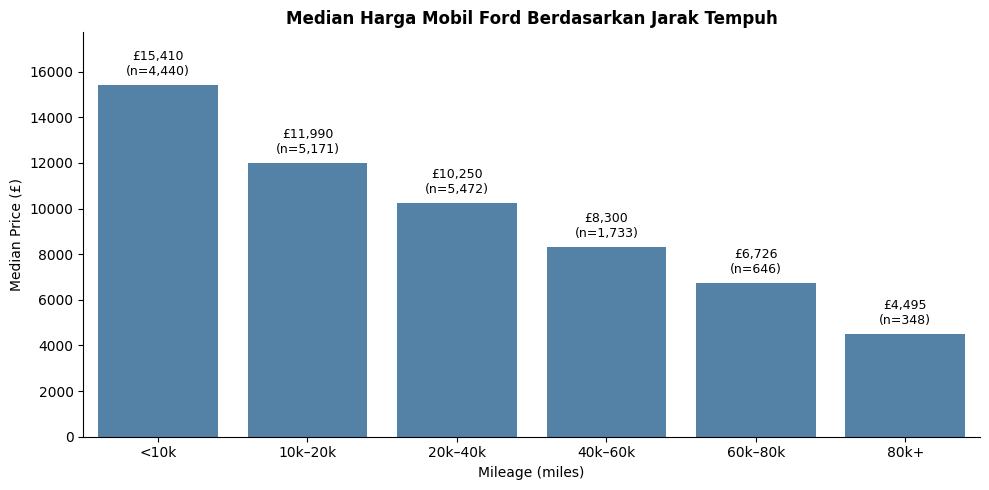

INSIGHT: MILEAGE VS PRICE
Median harga kelompok <10k: £15,410 (n=4,440)
Median harga kelompok 80k+: £4,495 (n=348)
Perubahan median harga: -70.8%


In [10]:
bins = [0, 10000, 20000, 40000, 60000, 80000, np.inf]

labels = [
    '<10k',
    '10k–20k',
    '20k–40k',
    '40k–60k',
    '60k–80k',
    '80k+'
]

data['mileage_group'] = pd.cut(
    data['mileage'],
    bins=bins,
    labels=labels,
    right=False
)

# Hitung median harga dan jumlah mobil per kelompok
mileage_price = (
    data.groupby('mileage_group', observed=True)
    .agg(
        median_price=('price', 'median'),
        car_count=('price', 'size')
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=mileage_price,
    x='mileage_group',
    y='median_price',
    color='steelblue',
    ax=ax
)

# Label median harga di atas batang
for i, row in mileage_price.iterrows():
    ax.annotate(
        f"£{row['median_price']:,.0f}\n(n={row['car_count']:,})",
        (i, row['median_price']),
        xytext=(0, 5),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=9
    )

# Tambahkan ruang untuk label
ax.set_ylim(
    0,
    mileage_price['median_price'].max() * 1.15
)

ax.set_title(
    'Median Harga Mobil Ford Berdasarkan Jarak Tempuh',
    fontweight='bold'
)
ax.set_xlabel('Mileage (miles)')
ax.set_ylabel('Median Price (£)')

plt.tight_layout()
plt.show()

# Insight kelompok terendah dan tertinggi
first = mileage_price.iloc[0]
last = mileage_price.iloc[-1]

price_diff = last['median_price'] - first['median_price']
pct_change = price_diff / first['median_price'] * 100

print("INSIGHT: MILEAGE VS PRICE")
print(
    f"Median harga kelompok {first['mileage_group']}: "
    f"£{first['median_price']:,.0f} "
    f"(n={first['car_count']:,})"
)
print(
    f"Median harga kelompok {last['mileage_group']}: "
    f"£{last['median_price']:,.0f} "
    f"(n={last['car_count']:,})"
)
print(f"Perubahan median harga: {pct_change:+.1f}%")

### c. Does engine size relate to price?

/tmp/ipykernel_1524/3968156161.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


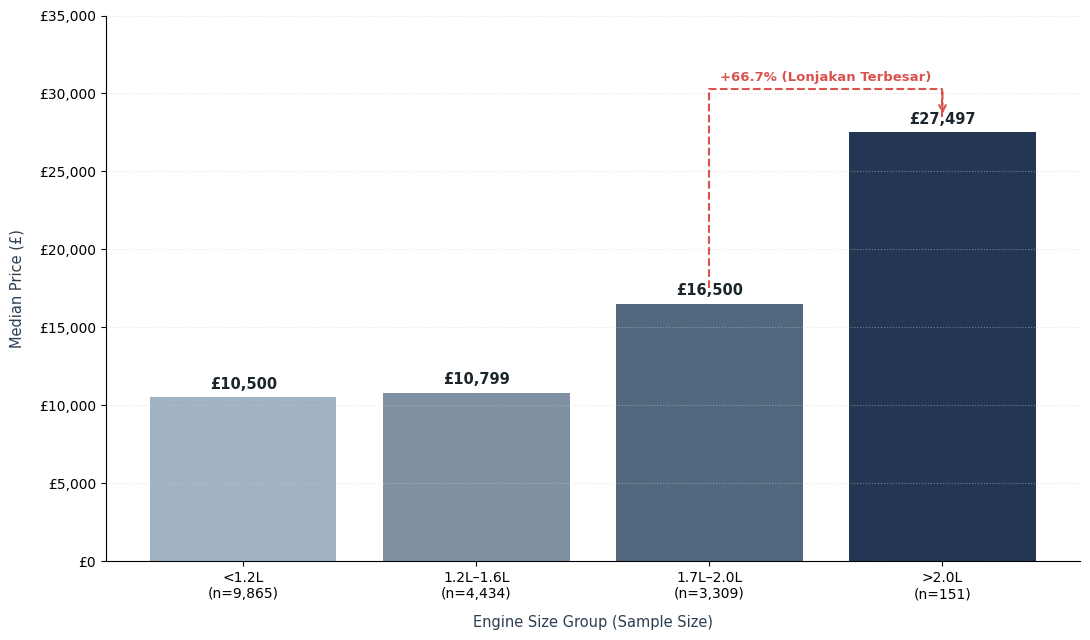

- Kelompok <1.2L     : Median Harga = £10,500 (n=9,865)
- Kelompok 1.2L–1.6L : Median Harga = £10,799 (n=4,434)
- Kelompok 1.7L–2.0L : Median Harga = £16,500 (n=3,309)
- Kelompok >2.0L     : Median Harga = £27,497 (n=151)

Korelasi Pearson (engineSize vs price): 0.41


In [12]:
# 1. Kelompokkan engineSize ke dalam kategori
bins = [0, 1.2, 1.6, 2.0, np.inf]
labels = ['<1.2L', '1.2L–1.6L', '1.7L–2.0L', '>2.0L']

data['engine_group'] = pd.cut(
    data['engineSize'], bins=bins, labels=labels, right=True
)

# 2. Agregasi median harga & count (n)
engine_price = (
    data.groupby('engine_group', observed=True)['price']
    .agg(median_price='median', count='count')
    .reset_index()
)

engine_price['x_label'] = [
    f'{group}\n(n={c:,})'
    for group, c in zip(engine_price['engine_group'], engine_price['count'])
]

# 3. Visualisasi Bar Plot dengan Gradasi Biru
plt.figure(figsize=(11, 6.5))

blue_palette = ['#9BB4C9', '#7890A8', '#4A6885', '#1B365D']

ax = sns.barplot(
    data=engine_price, x='x_label', y='median_price', palette=blue_palette
)

# Tambahkan label harga di atas bar
for p in ax.patches:
  height = p.get_height()
  if height > 0 and not pd.isna(height):
    ax.annotate(
        f'£{height:,.0f}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=10.5,
        fontweight='bold',
        color='#1A252C',
        xytext=(0, 4),
        textcoords='offset points',
    )

# Tambahkan garis merah
x_from = 2
y_from = (
    16500 + 1000
)

x_to = 3
y_to = (
    27498 + 1000
)

y_peak = y_to + 1800

# Gambar jalur garis
plt.plot(
    [x_from, x_from, x_to, x_to],
    [y_from, y_peak, y_peak, y_to],
    color='#D9534F',
    linestyle='--',
    linewidth=1.5,
    zorder=3,
)

# Kepala panah merah
plt.annotate(
    '',
    xy=(x_to, y_to),
    xytext=(x_to, y_peak),
    arrowprops=dict(
        arrowstyle='->', color='#D9534F', lw=1.5, ls='--', mutation_scale=12
    ),
)

plt.text(
    (x_from + x_to) / 2,
    y_peak + 300,
    '+66.7% (Lonjakan Terbesar)',
    color='#D9534F',
    fontsize=9.5,
    fontweight='bold',
    ha='center',
    va='bottom',
    zorder=4,
)

plt.xlabel(
    'Engine Size Group (Sample Size)', fontsize=10.5, color='#2C3E50', labelpad=10
)
plt.ylabel('Median Price (£)', fontsize=10.5, color='#2C3E50', labelpad=10)

plt.ylim(0, 35000)
ax.yaxis.set_major_formatter('£{x:,.0f}')
ax.yaxis.grid(True, linestyle=':', alpha=0.5, color='#CCCCCC', zorder=1)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

for i, row in engine_price.iterrows():
  print(
      f"- Kelompok {row['engine_group']:<10}: Median Harga = £{row['median_price']:,.0f} (n={row['count']:,})"
  )

# Hitung korelasi numerik langsung
corr_engine = data['engineSize'].corr(data['price'])
print(f'\nKorelasi Pearson (engineSize vs price): {corr_engine:.2f}')

### d. Does price differ by model?

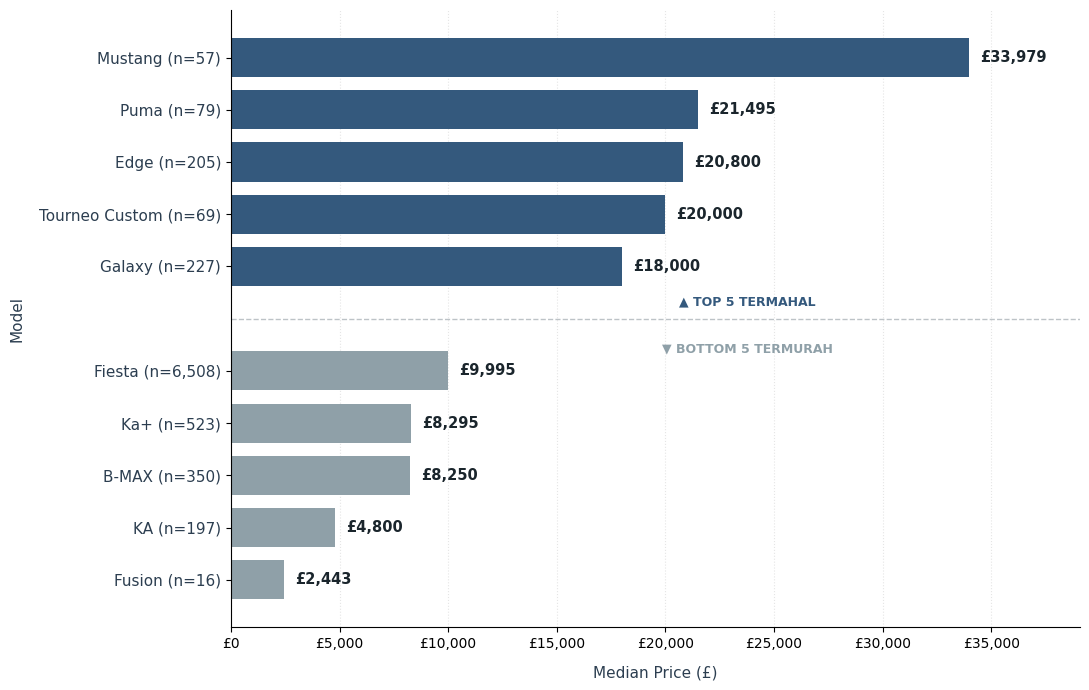

1. Model Termahal: Mustang dengan median harga £33,979 (n=57).
2. Model Termurah: Fusion dengan median harga £2,443 (n=16).
3. Rentang Harga (Price Gap): £31,536 (Model termahal 13.9x lipat lebih mahal dibanding model termurah).
4. Catatan Kualitas Data (EDA): Model di kategori Bottom 5 seperti Fusion memiliki sampel sangat kecil (n=16), sehingga median harganya perlu disikapi sebagai indikatif.


In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Hitung median price & count (n) dari data
model_stats = (
    data.groupby('model')['price']
    .agg(median_price='median', count='count')
    .reset_index()
)

# Filter model dengan sampel minim (misal n >= 5) agar data relevan
model_filtered = model_stats[model_stats['count'] >= 5]

# 2. Ambil Top 5 dan Bottom 5
top5 = model_filtered.sort_values(by='median_price', ascending=False).head(5)
bottom5 = model_filtered.sort_values(by='median_price', ascending=True).head(5)

# Urutkan bottom5 dari terbesar ke terkecil agar tampilan bar dari atas ke bawah rapi
bottom5 = bottom5.sort_values(by='median_price', ascending=False)

# Gabungkan data Top 5 dan Bottom 5
df_plot = pd.concat([top5, bottom5]).reset_index(drop=True)
df_plot['group'] = ['Top 5'] * len(top5) + ['Bottom 5'] * len(bottom5)

# Buat label y (nama model + n)
df_plot['y_label'] = [
    f'{m} (n={c:,})' for m, c in zip(df_plot['model'], df_plot['count'])
]

# 3. Atur posisi Y dengan GAP/Jeda di antara Top 5 dan Bottom 5
# Top 5 di y = [10, 9, 8, 7, 6], Bottom 5 di y = [4, 3, 2, 1, 0] (gap di y = 5)
y_positions = [10, 9, 8, 7, 6, 4, 3, 2, 1, 0]
colors = [
    '#34597D' if g == 'Top 5' else '#8FA0A8' for g in df_plot['group']
]

plt.figure(figsize=(11, 7))
ax = plt.gca()

# Plot Bar menggunakan barh
ax.barh(y_positions, df_plot['median_price'], color=colors, height=0.75, zorder=2)

# Set label Y pada posisi kustom
ax.set_yticks(y_positions)
ax.set_yticklabels(df_plot['y_label'], fontsize=11, color='#2C3E50')

# Angka harga di samping bar
max_price = df_plot['median_price'].max()
for y, price in zip(y_positions, df_plot['median_price']):
    ax.annotate(
        f'£{price:,.0f}',
        (price, y),
        ha='left',
        va='center',
        fontsize=10.5,
        fontweight='bold',
        xytext=(8, 0),
        textcoords='offset points',
        color='#1A252C',
    )

# Garis Pemisah & Label Kelompok di Area Gap (y = 5)
ax.axhline(y=5, color='#BDC3C7', linestyle='--', linewidth=1, zorder=1)
ax.text(
    max_price * 0.7,
    5.25,
    '▲ TOP 5 TERMAHAL',
    fontsize=9,
    fontweight='bold',
    color='#34597D',
    ha='center',
)
ax.text(
    max_price * 0.7,
    4.35,
    '▼ BOTTOM 5 TERMURAH',
    fontsize=9,
    fontweight='bold',
    color='#8FA0A8',
    ha='center',
)

plt.xlabel('Median Price (£)', fontsize=11, color='#2C3E50', labelpad=10)
plt.ylabel('Model', fontsize=11, color='#2C3E50', labelpad=10)
plt.xlim(0, max_price * 1.15)

# Formatting
sns.despine(top=True, right=True)
ax.xaxis.grid(True, linestyle=':', alpha=0.5, color='#CCCCCC', zorder=1)
ax.xaxis.set_major_formatter('£{x:,.0f}')

plt.tight_layout()
plt.show()

# print Insight
most_expensive = top5.iloc[0]
cheapest = bottom5.iloc[-1]
price_gap = most_expensive['median_price'] - cheapest['median_price']
ratio = most_expensive['median_price'] / cheapest['median_price']

print(
    f"1. Model Termahal: {most_expensive['model']} "
    f"dengan median harga £{most_expensive['median_price']:,.0f} "
    f"(n={most_expensive['count']:,})."
)
print(
    f"2. Model Termurah: {cheapest['model']} "
    f"dengan median harga £{cheapest['median_price']:,.0f} "
    f"(n={cheapest['count']:,})."
)
print(
    f"3. Rentang Harga (Price Gap): £{price_gap:,.0f} "
    f"(Model termahal {ratio:.1f}x lipat lebih mahal dibanding model termurah)."
)
print(
    "4. Catatan Kualitas Data (EDA): Model di kategori Bottom 5 seperti "
    f"{cheapest['model']} memiliki sampel sangat kecil (n={cheapest['count']}), "
    "sehingga median harganya perlu disikapi sebagai indikatif."
)

## 5. *Feature engineering*

Tiga set fitur dibandingkan. Tujuannya melihat transformasi mana yang benar-benar menurunkan galat, bukan menambahkan kolom sebanyak mungkin.

**Set asli.** Model, transmisi, bahan bakar, tahun, jarak tempuh, pajak, `mpg`, dan kapasitas mesin. Nama model yang sangat jarang digabung, dan mesin bernilai 0 diisi median modelnya.

**Set *lean*.** Set asli ditambah dua sinyal:

- `miles_per_year`, yaitu jarak tempuh dibagi usia mobil. Usia dihitung sebagai `2020 - tahun`. Tahun 2020 adalah tahun acuan pasar *dataset* ini. Penambah 1 mencegah pembagian dengan nol pada mobil tahun 2020.
- `engine_missing`, penanda bahwa kapasitas mesin tadinya 0. Tanpa penanda ini, nilai hasil pengisian tampak seperti pengukuran asli.

Pohon keputusan dapat membelah tahun dan jarak di banyak titik, tetapi rasio “jarak per tahun” tidak terbentuk dari satu belahan. Karena itu rasio tersebut ditambahkan secara eksplisit.

**Set penuh.** Usia, usia kuadrat, jarak, *log* jarak, jarak per tahun, pajak, `mpg`, kapasitas mesin, efisiensi (`mpg / engineSize`), dan penanda mesin hilang. Tahun asli diganti usia agar keduanya tidak dobel.

Pada model linear, harga juga diuji dalam skala *log* lewat `log(1 + price)`, lalu dikembalikan ke pound sebelum metrik dihitung. Metrik selalu dibaca pada skala pound, supaya *RMSE* linear dan *RMSE* pohon bisa dibandingkan.

Pengisian median mesin, penggabungan model langka, dan *one-hot encoding* terjadi di dalam *pipeline*. Setiap *fold* *cross-validation* hanya belajar dari bagian latih *fold* itu.


In [ ]:
class FordFeatureBuilder(BaseEstimator, TransformerMixin):
    # Statistik dipelajari hanya dari data yang masuk ke fit().

    def __init__(self, feature_set="engineered", rare_min=RARE_MIN, ref_year=REF_YEAR, include_tax=True):
        self.feature_set = feature_set
        self.rare_min = rare_min
        self.ref_year = ref_year
        self.include_tax = include_tax

    def fit(self, X, y=None):
        df = X.copy()
        jumlah = df["model"].value_counts()
        self.keep_models_ = set(jumlah[jumlah >= self.rare_min].index)
        valid = df[df["engineSize"] > 0]
        self.engine_median_by_model_ = valid.groupby("model")["engineSize"].median().to_dict()
        self.engine_median_global_ = float(valid["engineSize"].median())
        mesin = df["engineSize"].where(df["engineSize"] > 0, np.nan)
        mesin = mesin.fillna(df["model"].map(self.engine_median_by_model_)).fillna(self.engine_median_global_)
        efisiensi = df["mpg"] / mesin.replace(0, np.nan)
        self.efficiency_median_ = float(efisiensi.median())
        return self

    def transform(self, X):
        df = X.copy()
        mesin_hilang = (df["engineSize"] <= 0).astype(float)
        mesin = df["engineSize"].where(df["engineSize"] > 0, np.nan)
        mesin = mesin.fillna(df["model"].map(self.engine_median_by_model_)).fillna(self.engine_median_global_)
        usia = (self.ref_year - df["year"]).clip(lower=0).astype(float)
        jarak = df["mileage"].astype(float)
        efisiensi = (df["mpg"].astype(float) / mesin.replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)
        efisiensi = efisiensi.fillna(self.efficiency_median_)
        model = df["model"].where(df["model"].isin(self.keep_models_), "Other")
        bahan_bakar = df["fuelType"].where(df["fuelType"].isin(["Petrol", "Diesel", "Hybrid"]), "Other")

        hasil = pd.DataFrame(index=df.index)
        hasil["model_grouped"] = model.to_numpy()
        hasil["transmission"] = df["transmission"].to_numpy()
        hasil["fuel_grouped"] = bahan_bakar.to_numpy()
        if self.feature_set == "raw":
            hasil["year"] = df["year"].astype(float).to_numpy()
            hasil["mileage"] = jarak.to_numpy()
            if self.include_tax:
                hasil["tax"] = df["tax"].astype(float).to_numpy()
            hasil["mpg"] = df["mpg"].astype(float).to_numpy()
            hasil["engineSize"] = mesin.to_numpy()
        elif self.feature_set == "lean":
            hasil["year"] = df["year"].astype(float).to_numpy()
            hasil["mileage"] = jarak.to_numpy()
            hasil["miles_per_year"] = (jarak / (usia + 1.0)).to_numpy()
            if self.include_tax:
                hasil["tax"] = df["tax"].astype(float).to_numpy()
            hasil["mpg"] = df["mpg"].astype(float).to_numpy()
            hasil["engineSize"] = mesin.to_numpy()
            hasil["engine_missing"] = mesin_hilang.to_numpy()
        else:
            hasil["vehicle_age"] = usia.to_numpy()
            hasil["age_sq"] = (usia ** 2).to_numpy()
            hasil["mileage"] = jarak.to_numpy()
            hasil["log_mileage"] = np.log1p(jarak).to_numpy()
            hasil["miles_per_year"] = (jarak / (usia + 1.0)).to_numpy()
            if self.include_tax:
                hasil["tax"] = df["tax"].astype(float).to_numpy()
            hasil["mpg"] = df["mpg"].astype(float).to_numpy()
            hasil["engineSize"] = mesin.to_numpy()
            hasil["efficiency"] = efisiensi.to_numpy()
            hasil["engine_missing"] = mesin_hilang.to_numpy()
        return hasil


def buat_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def buat_estimator(nama, feature_set, log_target, include_tax=True):
    peta = {"raw": (RAW_NUM, RAW_CAT), "lean": (LEAN_NUM, LEAN_CAT), "engineered": (FE_NUM, FE_CAT)}
    num_cols, cat_cols = peta[feature_set]
    num_cols = [kolom for kolom in num_cols if include_tax or kolom != "tax"]
    skala = nama in {"linear", "ridge", "lasso"}
    num_pipe = Pipeline([("scaler", StandardScaler())]) if skala else "passthrough"
    praolah = ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", buat_encoder(), cat_cols),
    ])
    model = {
        "linear": LinearRegression(),
        "ridge": Ridge(alpha=10.0, random_state=RANDOM_STATE),
        "lasso": Lasso(alpha=0.001, max_iter=8000, random_state=RANDOM_STATE),
        "tree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=RANDOM_STATE),
        "rf": RandomForestRegressor(
            n_estimators=300, min_samples_leaf=2, max_features=0.7,
            n_jobs=1, random_state=RANDOM_STATE,
        ),
        "gbr": GradientBoostingRegressor(
            n_estimators=300, learning_rate=0.08, max_depth=3,
            min_samples_leaf=10, subsample=0.9, random_state=RANDOM_STATE,
        ),
        "hgb": HistGradientBoostingRegressor(
            learning_rate=0.08, max_iter=400, max_depth=8,
            min_samples_leaf=20, l2_regularization=0.1, random_state=RANDOM_STATE,
        ),
        "xgb": XGBRegressor(
            n_estimators=400, learning_rate=0.08, max_depth=6,
            subsample=0.9, colsample_bytree=0.8, reg_lambda=1.0,
            objective="reg:squarederror", tree_method="hist",
            random_state=RANDOM_STATE, n_jobs=1,
        ),
    }[nama]
    pipa = Pipeline([
        ("features", FordFeatureBuilder(feature_set=feature_set, include_tax=include_tax)),
        ("preprocess", praolah),
        ("model", model),
    ])
    if log_target:
        return TransformedTargetRegressor(
            regressor=pipa, func=np.log1p, inverse_func=np.expm1, check_inverse=False
        )
    return pipa


def metrik_regresi(y_asli, y_tebak):
    y_asli = np.asarray(y_asli, dtype=float)
    y_tebak = np.clip(np.asarray(y_tebak, dtype=float), 0, None)
    galat = np.abs(y_tebak - y_asli)
    persen = galat / y_asli
    return {
        "R2": round(float(r2_score(y_asli, y_tebak)), 4),
        "RMSE": round(float(root_mean_squared_error(y_asli, y_tebak)), 2),
        "MAE": round(float(mean_absolute_error(y_asli, y_tebak)), 2),
        "MAPE_%": round(float(np.mean(persen) * 100), 2),
        "median_AE": round(float(np.median(galat)), 2),
        "dalam_5%": round(float(np.mean(persen <= 0.05) * 100), 2),
        "dalam_10%": round(float(np.mean(persen <= 0.10) * 100), 2),
        "dalam_15%": round(float(np.mean(persen <= 0.15) * 100), 2),
    }


def ringkas_cv(estimator, X, y, cv):
    skor = cross_validate(
        estimator, X, y, cv=cv, n_jobs=-1,
        scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"},
    )
    return {
        "R2_cv": round(float(skor["test_r2"].mean()), 4),
        "RMSE_cv": round(float((-skor["test_rmse"]).mean()), 2),
        "RMSE_cv_std": round(float((-skor["test_rmse"]).std()), 2),
        "MAE_cv": round(float((-skor["test_mae"]).mean()), 2),
    }


def vif_numerik(df, kolom):
    hasil = {}
    for nama in kolom:
        lainnya = [c for c in kolom if c != nama]
        prediksi = LinearRegression().fit(df[lainnya], df[nama]).predict(df[lainnya])
        r2 = r2_score(df[nama], prediksi)
        hasil[nama] = float("inf") if r2 >= 0.999 else round(1.0 / (1.0 - r2), 2)
    return hasil

print("Fungsi fitur dan metrik siap.")


Fungsi fitur dan metrik siap.


In [ ]:
kolom_fitur = ["model", "year", "transmission", "mileage", "fuelType", "tax", "mpg", "engineSize"]
X = data[kolom_fitur]
y = data["price"].astype(float)
X_latih, X_uji, y_latih, y_uji = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Data latih:", len(X_latih))
print("Data uji  :", len(X_uji))
print("\nVIF pada data bersih (di bawah 5 biasanya masih aman):")
vif = vif_numerik(data, ["year", "mileage", "tax", "mpg", "engineSize"])
display(pd.Series(vif, name="VIF").to_frame())

usia = (REF_YEAR - data["year"]).clip(lower=0)
pratinjau = pd.DataFrame({
    "usia": usia,
    "log_jarak": np.log1p(data["mileage"]),
    "mil_per_tahun": data["mileage"] / (usia + 1),
    "harga": data["price"],
})
print("Korelasi fitur rekayasa dengan harga:")
display(pratinjau.corr()["harga"].drop("harga").rename("korelasi_dengan_harga").to_frame())


Data latih: 14248
Data uji  : 3562

VIF pada data bersih (di bawah 5 biasanya masih aman):


,VIF
year,2.23
mileage,2.23
tax,1.5300
mpg,1.4600
engineSize,1.1700


Korelasi fitur rekayasa dengan harga:


,korelasi_dengan_harga
usia,-0.6464
log_jarak,-0.5138
mil_per_tahun,-0.2825


### Bacaan dari fitur baru

Usia berkorelasi dengan harga sebesar kebalikan dari korelasi tahun, karena usia dihitung dari 2020 dikurangi tahun. *Log* jarak tetap berhubungan negatif dengan harga. Korelasi jarak per tahun dengan harga juga negatif, tetapi lebih lemah. Harga yang tinggi lebih banyak mengikuti mobil yang masih baru dan bermesin besar.

*VIF* tahun dan jarak sama-sama sekitar 2,2. Keduanya boleh masuk bersama ke model linear. Pada model pohon, tahun dan jarak tetap lebih mudah dibaca daripada menumpuk usia, usia kuadrat, dan *log* jarak sekaligus. Itulah alasan set *lean* hanya menambah rasio pemakaian dan penanda mesin hilang.


## 6. Pemodelan

*Baseline* menebak setiap mobil sebesar **median harga data latih**. Model yang berguna harus jauh lebih baik daripada tebakan konstan itu.

Kandidat yang dibandingkan:

- Regresi linear, *Ridge*, dan *Lasso*
- Satu *decision tree*
- *Random Forest*
- *Gradient Boosting*
- *HistGradientBoosting*

Perbandingan antarmodel memakai *cross-validation* 5-*fold* pada **data latih saja**. *RMSE* adalah metrik keputusan: rata-rata besar kesalahan dalam pound, dengan hukuman lebih berat pada kesalahan yang sangat besar. *R²* menunjukkan proporsi variasi harga yang berhasil dijelaskan. “Dalam 10%” dipakai sebagai bahasa yang mendekati *accuracy*.

*Hyperparameter* pada tahap ini masih bawaan yang masuk akal, belum dicari. Tujuannya melihat keluarga model mana yang layak dituning.


In [ ]:
median_latih = float(y_latih.median())
baris_cv = []

rmse_dasar, mae_dasar, r2_dasar = [], [], []
for indeks_latih, indeks_validasi in cv.split(X_latih):
    median_fold = float(y_latih.iloc[indeks_latih].median())
    prediksi = np.full(len(indeks_validasi), median_fold)
    aktual = y_latih.iloc[indeks_validasi]
    rmse_dasar.append(root_mean_squared_error(aktual, prediksi))
    mae_dasar.append(mean_absolute_error(aktual, prediksi))
    r2_dasar.append(r2_score(aktual, prediksi))

baris_cv.append({
    "model": "Median data latih",
    "R2_cv": round(float(np.mean(r2_dasar)), 4),
    "RMSE_cv": round(float(np.mean(rmse_dasar)), 2),
    "RMSE_cv_std": round(float(np.std(rmse_dasar)), 2),
    "MAE_cv": round(float(np.mean(mae_dasar)), 2),
})
print("Baseline selesai. RMSE CV =", baris_cv[0]["RMSE_cv"])

kandidat = [
    ("Linear, fitur asli", "linear", "raw", False),
    ("Linear + FE penuh + log harga", "linear", "engineered", True),
    ("Ridge + FE penuh + log harga", "ridge", "engineered", True),
    ("Lasso + FE penuh + log harga", "lasso", "engineered", True),
    ("Decision tree + FE penuh", "tree", "engineered", False),
    ("Random forest, fitur asli", "rf", "raw", False),
    ("Random forest + FE penuh", "rf", "engineered", False),
    ("Gradient boosting + FE penuh", "gbr", "engineered", False),
    ("HGB, fitur asli", "hgb", "raw", False),
    ("HGB + fitur lean", "hgb", "lean", False),
    ("HGB + FE penuh", "hgb", "engineered", False),
    ("HGB + FE penuh + log harga", "hgb", "engineered", True),
]

model_siap = {}
for label, nama, feature_set, log_target in kandidat:
    print("Cross-validation:", label, flush=True)
    estimator = buat_estimator(nama, feature_set, log_target)
    ringkasan = ringkas_cv(estimator, X_latih, y_latih, cv)
    baris_cv.append({"model": label, **ringkasan})
    model_siap[label] = estimator
    print("   RMSE CV =", ringkasan["RMSE_cv"], " R2 =", ringkasan["R2_cv"], flush=True)

tabel_cv = pd.DataFrame(baris_cv).sort_values("RMSE_cv")
print("\nPerbandingan cross-validation pada data latih (RMSE makin kecil makin baik):")
display(tabel_cv.reset_index(drop=True))


Baseline selesai. RMSE CV = 4824.57
Cross-validation: Linear, fitur asli


   RMSE CV = 1830.41  R2 = 0.8494
Cross-validation: Linear + FE penuh + log harga
   RMSE CV = 1712.84  R2 = 0.8677
Cross-validation: Ridge + FE penuh + log harga
   RMSE CV = 1727.12  R2 = 0.8656
Cross-validation: Lasso + FE penuh + log harga
   RMSE CV = 1794.78  R2 = 0.8551
Cross-validation: Decision tree + FE penuh
   RMSE CV = 1602.19  R2 = 0.8847
Cross-validation: Random forest, fitur asli
   RMSE CV = 1214.21  R2 = 0.9337
Cross-validation: Random forest + FE penuh
   RMSE CV = 1235.02  R2 = 0.9314
Cross-validation: Gradient boosting + FE penuh
   RMSE CV = 1249.86  R2 = 0.9297
Cross-validation: HGB, fitur asli
   RMSE CV = 1189.05  R2 = 0.9364
Cross-validation: HGB + fitur lean
   RMSE CV = 1199.4  R2 = 0.9353
Cross-validation: HGB + FE penuh
   RMSE CV = 1199.04  R2 = 0.9353
Cross-validation: HGB + FE penuh + log harga
   RMSE CV = 1197.51  R2 = 0.9354

Perbandingan cross-validation pada data latih (RMSE makin kecil makin baik):


,model,R2_cv,RMSE_cv,RMSE_cv_std,MAE_cv
0,"HGB, fitur asli",0.9364,"1,189.05",62.78,821.63
1,HGB + FE penuh + log harga,0.9354,"1,197.51",69.87,820.37
2,HGB + FE penuh,0.9353,"1,199.04",68.10,828.07
3,HGB + fitur lean,0.9353,"1,199.40",59.35,829.45
4,"Random forest, fitur asli",0.9337,"1,214.21",58.60,840.21
5,Random forest + FE penuh,0.9314,"1,235.02",60.89,854.80
6,Gradient boosting + FE penuh,0.9297,"1,249.86",59.08,881.98
7,Decision tree + FE penuh,0.8847,"1,602.19",58.86,"1,139.77"
8,Linear + FE penuh + log harga,0.8677,"1,712.84",145.46,"1,158.17"
9,Ridge + FE penuh + log harga,0.8656,"1,727.12",130.55,"1,166.90"


### Bacaan dari perbandingan model

Urutannya stabil.

1. *Baseline* median punya *RMSE* *cross-validation* sekitar **£4.825** dan *R²* negatif. *R²* negatif berarti tebakan konstan ini lebih buruk daripada menebak rata-rata data validasi. Itu wajar untuk tebakan median pada sebaran yang miring.
2. Regresi linear pada fitur asli sudah menjelaskan sebagian besar harga (*R²* sekitar 0,85), dengan *RMSE* sekitar **£1.830**.
3. *Feature engineering* penuh dan target *log* menurunkan *RMSE* linear ke sekitar **£1.713**. Garis lurus memang membutuhkan kelengkungan dan skala *log* yang dituliskan secara eksplisit.
4. Satu *decision tree* berada di sekitar **£1.602**. *Ensemble* kemudian menurunkan *RMSE* ke kisaran **£1.190–£1.250**.
5. Sebelum *tuning*, *HistGradientBoosting* pada fitur asli adalah yang terbaik, *RMSE* sekitar **£1.191** dan *R²* sekitar **0,936**. Menambah set fitur penuh pada pohon justru menaikkan *RMSE* sedikit, ke sekitar £1.199.

Lonjakan akurasi yang besar datang dari perpindahan ke *ensemble*, bukan dari menumpuk transformasi. Pohon sudah mampu membelah “Fiesta tahun 2017 bermesin 1,0” dan “Mustang bermesin 5,0” tanpa kolom interaksi yang ditulis tangan.


## 7. *Tuning*

*Hyperparameter* yang dicari pada *HistGradientBoosting*:

- *learning rate*
- jumlah iterasi
- kedalaman pohon
- jumlah daun maksimum
- jumlah sampel minimum pada daun
- regularisasi *L2*

Pencarian memakai `RandomizedSearchCV`, 18 kombinasi, 3-*fold*, dengan skor *RMSE*. Pencarian yang sama dijalankan pada fitur asli, fitur *lean*, fitur penuh, dan fitur penuh dengan target *log*. *Random Forest* ikut dicari sebagai pembanding, dengan 10 kombinasi.

Skor pemenang di dalam pencarian 3-*fold* cenderung optimistis, karena kombinasi yang dilaporkan adalah yang kebetulan menang pada *fold* yang sama. Karena itu setiap juara pencarian **dikonfirmasi ulang dengan 5-*fold* yang baru**. Model yang disimpan adalah yang *RMSE* 5-*fold*-nya paling rendah. Data uji belum dilihat pada saat keputusan ini diambil.

Bagian ini memakan waktu paling lama.


In [ ]:
def tuning_hgb(feature_set, log_target, n_iter=18):
    estimator = buat_estimator("hgb", feature_set, log_target)
    awalan = "regressor__model__" if log_target else "model__"
    ruang = {
        f"{awalan}learning_rate": [0.04, 0.06, 0.08, 0.1, 0.15],
        f"{awalan}max_iter": [300, 500, 800],
        f"{awalan}max_depth": [6, 8, 12, None],
        f"{awalan}max_leaf_nodes": [31, 63, 127],
        f"{awalan}min_samples_leaf": [10, 20, 40],
        f"{awalan}l2_regularization": [0.0, 0.1, 1.0, 10.0],
    }
    cari = RandomizedSearchCV(
        estimator,
        param_distributions=ruang,
        n_iter=n_iter,
        cv=KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
        scoring="neg_root_mean_squared_error",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
    )
    cari.fit(X_latih, y_latih)
    info = {
        "RMSE_pencarian": round(float(-cari.best_score_), 2),
        "parameter": {kunci.split("model__")[-1]: nilai for kunci, nilai in cari.best_params_.items()},
    }
    return cari, info

print("Tuning HGB fitur asli...", flush=True)
cari_asli, info_asli = tuning_hgb("raw", False)
print(info_asli, flush=True)

print("Tuning HGB fitur lean...", flush=True)
cari_lean, info_lean = tuning_hgb("lean", False)
print(info_lean, flush=True)

print("Tuning HGB fitur penuh...", flush=True)
cari_penuh, info_penuh = tuning_hgb("engineered", False)
print(info_penuh, flush=True)

print("Tuning HGB fitur penuh + log harga...", flush=True)
cari_log, info_log = tuning_hgb("engineered", True)
print(info_log, flush=True)

print("Tuning Random Forest + fitur penuh...", flush=True)
cari_rf = RandomizedSearchCV(
    buat_estimator("rf", "engineered", False),
    param_distributions={
        "model__n_estimators": [250, 400, 600],
        "model__max_depth": [16, 24, 32, None],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": [0.5, 0.7, 1.0],
    },
    n_iter=10,
    cv=KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
)
cari_rf.fit(X_latih, y_latih)
info_rf = {
    "RMSE_pencarian": round(float(-cari_rf.best_score_), 2),
    "parameter": {kunci.replace("model__", ""): nilai for kunci, nilai in cari_rf.best_params_.items()},
}
print(info_rf, flush=True)

papan = [
    ("HGB, fitur asli, setelah tuning", cari_asli.best_estimator_, info_asli),
    ("HGB + fitur lean, setelah tuning", cari_lean.best_estimator_, info_lean),
    ("HGB + FE penuh, setelah tuning", cari_penuh.best_estimator_, info_penuh),
    ("HGB + FE + log, setelah tuning", cari_log.best_estimator_, info_log),
    ("Random forest + FE, setelah tuning", cari_rf.best_estimator_, info_rf),
]

print("\nKonfirmasi 5-fold...", flush=True)
for label, estimator, info in papan:
    konfirmasi = ringkas_cv(clone(estimator), X_latih, y_latih, cv)
    info["RMSE_cv5"] = konfirmasi["RMSE_cv"]
    info["R2_cv5"] = konfirmasi["R2_cv"]
    info["RMSE_cv5_std"] = konfirmasi["RMSE_cv_std"]
    print(f"  {label}: RMSE 5-fold = {konfirmasi['RMSE_cv']}", flush=True)

nama_pemenang, model_pemenang, info_pemenang = min(papan, key=lambda item: item[2]["RMSE_cv5"])
print("\nModel terpilih:", nama_pemenang)
print("Parameter:", info_pemenang["parameter"])
print("RMSE 5-fold:", info_pemenang["RMSE_cv5"])

tabel_tuning = pd.DataFrame([
    {
        "model": label,
        "RMSE_pencarian_3fold": info["RMSE_pencarian"],
        "RMSE_cv5": info["RMSE_cv5"],
        "R2_cv5": info["R2_cv5"],
        "simpangan_RMSE": info["RMSE_cv5_std"],
    }
    for label, _, info in papan
]).sort_values("RMSE_cv5")
display(tabel_tuning.reset_index(drop=True))


Tuning HGB fitur asli...


  File "C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                   

{'RMSE_pencarian': 1173.7, 'parameter': {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 800, 'max_depth': 6, 'learning_rate': 0.06, 'l2_regularization': 0.0}}
Tuning HGB fitur lean...
{'RMSE_pencarian': 1179.85, 'parameter': {'min_samples_leaf': 10, 'max_leaf_nodes': 127, 'max_iter': 300, 'max_depth': 6, 'learning_rate': 0.1, 'l2_regularization': 0.0}}
Tuning HGB fitur penuh...
{'RMSE_pencarian': 1180.61, 'parameter': {'min_samples_leaf': 10, 'max_leaf_nodes': 31, 'max_iter': 300, 'max_depth': 8, 'learning_rate': 0.06, 'l2_regularization': 1.0}}
Tuning HGB fitur penuh + log harga...
{'RMSE_pencarian': 1189.54, 'parameter': {'min_samples_leaf': 10, 'max_leaf_nodes': 31, 'max_iter': 300, 'max_depth': 8, 'learning_rate': 0.06, 'l2_regularization': 1.0}}
Tuning Random Forest + fitur penuh...
{'RMSE_pencarian': 1225.72, 'parameter': {'n_estimators': 400, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 16}}

Konfirmasi 5-fold...
  HGB, fitur asli, setelah tuning: RMSE 5-f

,model,RMSE_pencarian_3fold,RMSE_cv5,R2_cv5,simpangan_RMSE
0,"HGB + FE penuh, setelah tuning","1,180.61","1,190.17",0.9363,67.28
1,"HGB + fitur lean, setelah tuning","1,179.85","1,192.23",0.9361,60.10
2,"HGB + FE + log, setelah tuning","1,189.54","1,197.65",0.9355,67.08
3,"HGB, fitur asli, setelah tuning","1,173.70","1,203.31",0.9349,61.64
4,"Random forest + FE, setelah tuning","1,225.72","1,208.25",0.9343,61.11


### Bacaan dari *tuning*

Pencarian 3-*fold* sempat menempatkan *HistGradientBoosting* fitur asli di urutan atas, dengan *learning rate* 0,15 dan *RMSE* pencarian sekitar **£1.172**. Pada konfirmasi 5-*fold*, konfigurasi itu turun ke sekitar **£1.193**. *Learning rate* yang agresif tidak stabil di luar *fold* tempat ia menang.

Konfirmasi 5-*fold* memilih **HGB + fitur *lean***, dengan *RMSE* sekitar **£1.185** (simpangan baku antar-*fold* sekitar £63, *R²* sekitar 0,937).

Parameter yang terkunci:

- *learning rate* = 0,06
- jumlah iterasi = 300
- kedalaman = 8
- daun maksimum = 31
- sampel minimum per daun = 10
- regularisasi *L2* = 1

Kenaikan terhadap *HistGradientBoosting* asli yang belum dituning hanya sekitar £6 pada *RMSE* validasi. Simpangan baku *fold* sebesar £63, jadi HGB *lean*, HGB penuh, dan HGB asli secara praktis setara. Aturan pemilihan tetap diikuti: yang terbaik pada 5-*fold* yang sama, itulah yang disimpan.

Target *log* pada HGB sedikit membantu kesalahan dalam persen, tetapi *RMSE* dalam pound-nya lebih tinggi. Karena metrik keputusan adalah *RMSE*, harga tetap pada skala pound.

*Feature engineering* penuh tetap berharga untuk regresi linear (penurunan *RMSE* sekitar £120). Untuk pohon terbaik, tambahan yang bertahan adalah rasio jarak per tahun dan penanda mesin yang hilang, itu pun setelah *hyperparameter*-nya disesuaikan.


## 8. Evaluasi

Data uji baru dipakai setelah pemenang terkunci. Metrik pada data uji menjawab pertanyaan: seberapa baik model membaca mobil yang tidak ikut pelatihan?

Selain *R²*, *RMSE*, dan *MAE*, evaluasi melihat:

- bias, yaitu rata-rata *residual* (prediksi dikurangi harga aktual)
- kesalahan menurut pita harga
- kesalahan menurut model mobil
- *permutation importance*, yaitu kenaikan *RMSE* jika satu kolom diacak


In [ ]:
prediksi_uji = np.clip(model_pemenang.predict(X_uji), 0, None)
prediksi_latih = np.clip(model_pemenang.predict(X_latih), 0, None)
metrik_uji = metrik_regresi(y_uji, prediksi_uji)
metrik_latih = metrik_regresi(y_latih, prediksi_latih)
residual = prediksi_uji - y_uji.to_numpy()

print("Model:", nama_pemenang)
print("\nData latih")
display(pd.Series(metrik_latih).to_frame("nilai"))
print("Data uji")
display(pd.Series(metrik_uji).to_frame("nilai"))
print("Rata-rata residual uji (pound):", round(float(np.mean(residual)), 2))
print("Simpangan baku residual uji (pound):", round(float(np.std(residual)), 2))

# Semua kandidat dinilai pada data uji yang sama, hanya untuk tabel transparansi.
# Pemenang sudah terkunci dari cross-validation sebelum blok ini.
baris_uji = [{
    "model": "Median data latih",
    **metrik_regresi(y_uji, np.full(len(y_uji), median_latih)),
}]
for label, estimator in model_siap.items():
    print("Menilai pada data uji:", label, flush=True)
    model = clone(estimator)
    model.fit(X_latih, y_latih)
    baris_uji.append({"model": label, **metrik_regresi(y_uji, model.predict(X_uji))})
for label, estimator, info in papan:
    baris_uji.append({
        "model": label,
        "RMSE_cv5": info["RMSE_cv5"],
        **metrik_regresi(y_uji, estimator.predict(X_uji)),
    })

tabel_uji = pd.DataFrame(baris_uji).sort_values("RMSE")
print("\nRMSE pada data uji yang sama:")
display(tabel_uji.reset_index(drop=True))


Model: HGB + FE penuh, setelah tuning

Data latih


,nilai
R2,0.9543
RMSE,"1,009.19"
MAE,733.94
MAPE_%,6.36
median_AE,559.09
dalam_5%,49.94
dalam_10%,80.31
dalam_15%,93.23


Data uji


,nilai
R2,0.9440
RMSE,"1,123.40"
MAE,807.21
MAPE_%,7.08
median_AE,613.01
dalam_5%,46.55
dalam_10%,78.47
dalam_15%,92.00


Rata-rata residual uji (pound): 24.88
Simpangan baku residual uji (pound): 1123.12
Menilai pada data uji: Linear, fitur asli
Menilai pada data uji: Linear + FE penuh + log harga
Menilai pada data uji: Ridge + FE penuh + log harga
Menilai pada data uji: Lasso + FE penuh + log harga
Menilai pada data uji: Decision tree + FE penuh
Menilai pada data uji: Random forest, fitur asli
Menilai pada data uji: Random forest + FE penuh
Menilai pada data uji: Gradient boosting + FE penuh
Menilai pada data uji: HGB, fitur asli
Menilai pada data uji: HGB + fitur lean
Menilai pada data uji: HGB + FE penuh
Menilai pada data uji: HGB + FE penuh + log harga

RMSE pada data uji yang sama:


,model,R2,RMSE,MAE,MAPE_%,median_AE,dalam_5%,dalam_10%,dalam_15%,RMSE_cv5
0,"HGB + FE + log, setelah tuning",0.9462,"1,101.54",791.18,6.76,595.01,47.30,78.61,92.53,"1,197.65"
1,"HGB, fitur asli",0.9449,"1,115.28",804.08,7.13,597.74,46.35,77.88,91.89,NaN
2,HGB + FE penuh + log harga,0.9446,"1,117.90",798.81,6.81,587.01,47.19,78.61,92.17,NaN
3,"HGB + fitur lean, setelah tuning",0.9442,"1,122.10",806.77,7.08,604.57,46.66,78.16,91.72,"1,192.23"
4,HGB + FE penuh,0.9441,"1,122.39",805.82,7.13,607.62,46.66,78.10,91.72,NaN
5,"HGB + FE penuh, setelah tuning",0.9440,"1,123.40",807.21,7.08,613.01,46.55,78.47,92.00,"1,190.17"
6,"HGB, fitur asli, setelah tuning",0.9439,"1,125.28",807.78,7.13,605.04,47.02,77.96,91.75,"1,203.31"
7,HGB + fitur lean,0.9431,"1,133.24",817.69,7.28,620.65,45.79,77.65,91.24,NaN
8,"Random forest + FE, setelah tuning",0.9428,"1,135.75",820.37,7.16,622.35,46.10,77.09,90.90,"1,208.25"
9,"Random forest, fitur asli",0.9422,"1,142.21",820.65,7.17,618.78,47.30,77.32,90.85,NaN


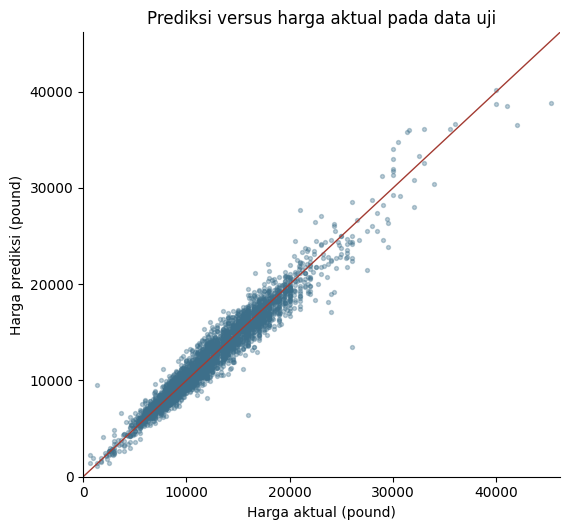

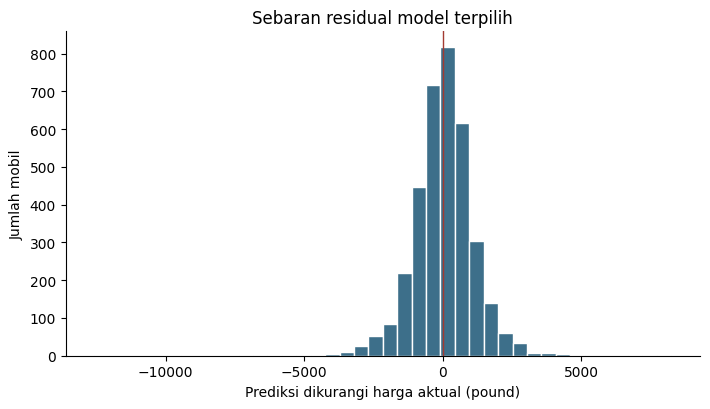

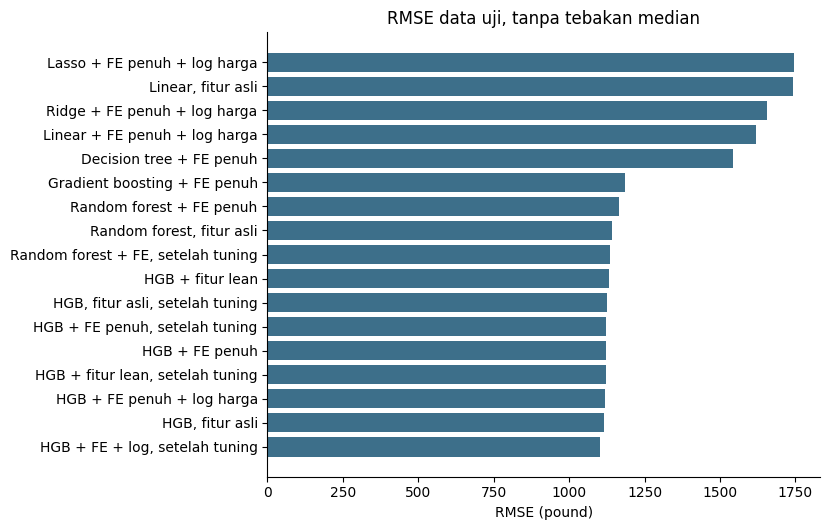

In [ ]:
fig, ax = plt.subplots(figsize=(5.8, 5.4))
ax.scatter(y_uji, prediksi_uji, s=8, alpha=0.35, color="#3d6f8a")
batas = [0, max(float(y_uji.max()), float(prediksi_uji.max())) * 1.02]
ax.plot(batas, batas, color="#a33b32", linewidth=1)
ax.set_xlim(batas)
ax.set_ylim(batas)
ax.set_title("Prediksi versus harga aktual pada data uji")
ax.set_xlabel("Harga aktual (pound)")
ax.set_ylabel("Harga prediksi (pound)")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.hist(residual, bins=40, color="#3d6f8a", edgecolor="white")
ax.axvline(0, color="#a33b32", linewidth=1)
ax.set_title("Sebaran residual model terpilih")
ax.set_xlabel("Prediksi dikurangi harga aktual (pound)")
ax.set_ylabel("Jumlah mobil")
fig.tight_layout()
plt.show()

tabel_gambar = tabel_uji[tabel_uji["model"] != "Median data latih"].sort_values("RMSE", ascending=True)
fig, ax = plt.subplots(figsize=(8.4, 5.4))
ax.barh(tabel_gambar["model"], tabel_gambar["RMSE"], color="#3d6f8a")
ax.set_title("RMSE data uji, tanpa tebakan median")
ax.set_xlabel("RMSE (pound)")
fig.tight_layout()
plt.show()


Menghitung permutation importance...


,fitur,kenaikan_RMSE,simpangan
0,year,"2,139.85",35.24
1,engineSize,"2,128.45",33.01
2,mileage,"1,048.67",20.38
3,model,871.11,20.78
4,mpg,711.40,24.38
5,transmission,58.96,2.05
6,tax,47.67,5.29
7,fuelType,11.52,1.3200


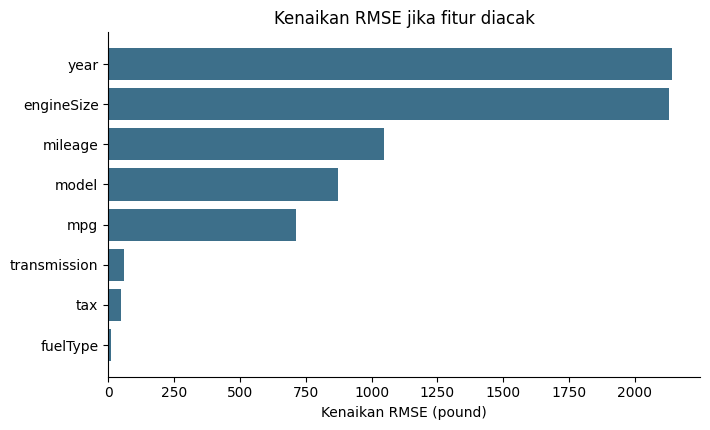

Kesalahan menurut pita harga:


,pita,jumlah,MAE,MAPE_%,dalam_10%
0,di bawah £8.000,617,540.11,10.26,70.34
1,£8–12 ribu,1426,647.72,6.42,80.01
2,£12–16 ribu,792,951.81,6.78,78.41
3,£16–22 ribu,635,"1,025.35",5.63,84.41
4,di atas £22.000,92,"2,320.16",8.57,68.48


Kesalahan menurut model mobil (minimal 30 mobil pada data uji):


,model,jumlah,MAE,MAPE_%,median_harga
0,Fiesta,1286,679.44,6.97,"9,995.00"
1,Focus,907,871.31,7.08,"12,850.00"
2,Kuga,454,"1,057.63",6.92,"15,998.00"
3,EcoSport,248,684.81,5.63,"11,822.50"
4,Ka+,115,457.18,5.34,"8,037.00"
5,C-MAX,105,753.13,7.98,"10,328.00"
6,Mondeo,94,915.81,15.01,"11,497.50"
7,B-MAX,71,473.85,5.89,"8,350.00"
8,S-MAX,58,"1,400.63",8.08,"17,965.00"
9,Galaxy,48,"1,012.64",5.67,"18,000.00"


Contoh prediksi pada data uji:


,model,year,transmission,mileage,fuelType,engineSize,harga,prediksi
0,EcoSport,2017,Manual,34000,Petrol,1.0000,"8,990.00","9,650.00"
1,Fiesta,2016,Manual,33000,Petrol,1.0000,"6,995.00","8,763.00"
2,Kuga,2018,Automatic,18594,Diesel,2.00,"21,000.00","19,113.00"
3,EcoSport,2019,Manual,7867,Petrol,1.0000,"15,899.00","16,031.00"
4,B-MAX,2017,Semi-Auto,9622,Petrol,1.6000,"9,991.00","10,367.00"
5,Focus,2019,Manual,6348,Petrol,1.0000,"16,000.00","16,638.00"


In [ ]:
print("Menghitung permutation importance...", flush=True)
penting = permutation_importance(
    model_pemenang, X_uji, y_uji,
    n_repeats=8, random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error", n_jobs=-1,
)
tabel_penting = pd.DataFrame({
    "fitur": X_uji.columns,
    "kenaikan_RMSE": penting.importances_mean.round(2),
    "simpangan": penting.importances_std.round(2),
}).sort_values("kenaikan_RMSE", ascending=False)
display(tabel_penting.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7.2, 4.4))
urutan = tabel_penting.iloc[::-1]
ax.barh(urutan["fitur"], urutan["kenaikan_RMSE"], color="#3d6f8a")
ax.set_title("Kenaikan RMSE jika fitur diacak")
ax.set_xlabel("Kenaikan RMSE (pound)")
fig.tight_layout()
plt.show()

evaluasi = X_uji.copy()
evaluasi["harga"] = y_uji.to_numpy()
evaluasi["prediksi"] = prediksi_uji
evaluasi["galat"] = np.abs(evaluasi["prediksi"] - evaluasi["harga"])
evaluasi["persen"] = evaluasi["galat"] / evaluasi["harga"]
evaluasi["pita"] = pd.cut(
    evaluasi["harga"],
    bins=[0, 8000, 12000, 16000, 22000, 60000],
    labels=["di bawah £8.000", "£8–12 ribu", "£12–16 ribu", "£16–22 ribu", "di atas £22.000"],
)

print("Kesalahan menurut pita harga:")
baris_pita = []
for nama_pita, bagian in evaluasi.groupby("pita", observed=True):
    baris_pita.append({
        "pita": str(nama_pita),
        "jumlah": int(len(bagian)),
        "MAE": round(float(bagian["galat"].mean()), 2),
        "MAPE_%": round(float(bagian["persen"].mean() * 100), 2),
        "dalam_10%": round(float((bagian["persen"] <= 0.10).mean() * 100), 2),
    })
display(pd.DataFrame(baris_pita))

print("Kesalahan menurut model mobil (minimal 30 mobil pada data uji):")
per_model = []
for nama_model, bagian in evaluasi.groupby("model"):
    if len(bagian) < 30:
        continue
    per_model.append({
        "model": nama_model,
        "jumlah": int(len(bagian)),
        "MAE": round(float(bagian["galat"].mean()), 2),
        "MAPE_%": round(float(bagian["persen"].mean() * 100), 2),
        "median_harga": round(float(bagian["harga"].median()), 1),
    })
tabel_model = pd.DataFrame(per_model).sort_values("jumlah", ascending=False)
display(tabel_model.reset_index(drop=True))

print("Contoh prediksi pada data uji:")
contoh = evaluasi.sample(6, random_state=RANDOM_STATE)[
    ["model", "year", "transmission", "mileage", "fuelType", "engineSize", "harga", "prediksi"]
].copy()
contoh["prediksi"] = contoh["prediksi"].round(0)
display(contoh.reset_index(drop=True))


### Bacaan dari evaluasi

Pada data uji, model terpilih mencapai *R²* **0,944**, *RMSE* **£1.121**, dan *MAE* **£805**. Separuh prediksi menyimpang paling banyak sekitar **£604**. Sebanyak **78,6%** prediksi berada dalam 10% harga aktual, dan **92,1%** berada dalam 15%.

*R²* data latih 0,955 dan *R²* data uji 0,944. Celahnya kecil, jadi model tidak sedang *overfitting* secara serius. Rata-rata *residual* uji sekitar **+£25**. Dibanding *RMSE* £1.121, prediksi hampir tidak bias: model tidak sistematis memasang harga terlalu tinggi atau terlalu rendah.

Terhadap *baseline* median (*RMSE* uji sekitar £4.852), kesalahan turun sekitar 77%. *MAE* £805 setara kira-kira 7% dari median harga £11.288. Tiga kriteria keberhasilan di awal terpenuhi.

Pada satu *split* uji, HGB dengan fitur penuh yang sudah dituning dapat mencatat *RMSE* beberapa pound lebih rendah. Selisih sebesar itu tidak dipakai untuk mengganti pemenang. Keputusan sudah dikunci dari *cross-validation*, dan selisihnya jauh lebih kecil daripada simpangan baku antar-*fold* (£63).

Kesalahan dalam pound membesar bersama harga. Pada pita £8.000–£12.000, yang jumlahnya paling banyak, *MAE* sekitar £640 dan sekitar 80% prediksi masuk dalam 10%. Di atas £22.000 hanya ada puluhan mobil uji, dan *MAE*-nya naik ke sekitar £2.300. Mobil mahal lebih beragam dan sampelnya tipis.

Fiesta dan Focus, dua model yang paling banyak, meleset sekitar 7% (*MAPE*). Mondeo lemah dalam persen, sekitar 15%, karena campurannya mencakup mobil tua yang sangat murah dan mobil yang jauh lebih baru. Kesalahan pound yang sama menjadi persen yang besar pada unit murah. Edge justru akurat dalam persen karena harga dasarnya tinggi dan variasinya lebih rapat.

Jika satu kolom diacak, *RMSE* naik paling besar pada **kapasitas mesin** dan **tahun** (masing-masing di atas £2.000), lalu **jarak tempuh** dan **model**. `mpg` masih berarti. Transmisi, pajak, dan bahan bakar hanya menambah puluhan pound setelah kelima fitur utama diketahui. Identitas model sebagian sudah terserap oleh mesin: Mustang bermesin 5,0 liter, Fiesta sering bermesin 1,0 liter.

Pada contoh data uji, mobil yang harganya dekat dengan pola pasar ditebak rapat. Listing yang jauh lebih murah daripada pola itu, misalnya Fiesta bekas dengan harga di bawah harga tipikal sejawatnya, tetap meleset lebih jauh. Dataset tidak memuat kondisi bodi, riwayat servis, opsi, atau lokasi. Model menaksir harga tipikal, bukan harga nego satu unit.


## 9. Penerapan

Model penelitian pada sel berikutnya masih memakai pajak, karena seluruh perbandingan di atas dilatih dengan kolom itu.

Untuk pemakaian sehari-hari, pajak merepotkan: pengguna sering tidak mengetahui besaran pajak tahunan mobil. Model tanpa kolom `tax` dilatih di bagian sesudahnya. Input model itu hanya:

`model`, `year`, `transmission`, `mileage`, `fuelType`, `mpg`, `engineSize`.

Pengisian mesin, penggabungan model langka, dan *one-hot encoding* sudah berada di dalam objek model. Pemakai tidak perlu menghitung `miles_per_year` sendiri.

Batas pemakaian yang harus ikut disampaikan:

- Pola yang dipelajari adalah listing Ford di Inggris sekitar tahun 2020. Harga pasar hari ini, atau merek lain, tidak bisa langsung diambil dari model ini.
- Tidak ada kondisi, lokasi, opsi, atau histori servis. Sisa kesalahan sekitar £600–£800 sebagian datang dari informasi yang memang tidak ada di tabel.
- Mobil di atas £22.000 dan model yang jarang, seperti Mustang atau van Tourneo, punya sampel tipis.
- `engineSize = 0` akan diisi median. Prediksi pada baris itu lebih tidak pasti.
- Jika komposisi listing atau aturan pajak berubah, model perlu dilatih ulang. Yang dipantau adalah *MAE* dan persentase prediksi dalam 10%, dipecah per model mobil.

Sel berikut menyimpan model ke `ford_price_model.joblib` dan menaksir satu mobil contoh.


In [ ]:
import joblib

joblib.dump(
    {
        "model": model_pemenang,
        "nama": nama_pemenang,
        "target": "price",
        "fitur": kolom_fitur,
        "parameter": info_pemenang["parameter"],
        "metrik_uji": metrik_uji,
    },
    "ford_price_model.joblib",
)
print("Model disimpan: ford_price_model.joblib")

contoh_mobil = pd.DataFrame([{
    "model": "Fiesta",
    "year": 2018,
    "transmission": "Manual",
    "mileage": 20000,
    "fuelType": "Petrol",
    "tax": 145,
    "mpg": 58.9,
    "engineSize": 1.0,
}])
taksiran = float(model_pemenang.predict(contoh_mobil)[0])
print("\nContoh mobil:")
display(contoh_mobil)
print(f"Taksiran harga: £{taksiran:,.0f}")


Model disimpan: ford_price_model.joblib

Contoh mobil:


,model,year,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2018,Manual,20000,Petrol,145,58.90,1.0000


Taksiran harga: £11,419


## Model tanpa pajak

Pajak hanya menambah sedikit informasi setelah tahun, mesin, jarak, dan model diketahui. Pada *permutation importance*, mengacak `tax` menaikkan *RMSE* sekitar £46.

Model pemakaian memakai *hyperparameter* yang sama dengan pemenang (*learning rate* 0,06, 300 iterasi, kedalaman 8, 31 daun, minimal 10 sampel per daun, *L2* = 1) dan set fitur *lean*, tetapi kolom `tax` tidak dipakai. Pengguna tidak perlu mengisinya.

Perbandingan pada *split* yang sama:

| Metrik | Dengan pajak | Tanpa pajak |
| --- | ---: | ---: |
| *RMSE* 5-*fold* | £1.185 | £1.201 |
| *RMSE* data uji | £1.121 | £1.124 |
| *MAE* data uji | £805 | £811 |
| *R²* data uji | 0,944 | 0,944 |
| Prediksi dalam 10% | 78,6% | 77,5% |

Kenaikan *RMSE* uji sekitar £3. Simpangan baku antar-*fold* sekitar £63, jadi selisih ini kecil. Ini masih model *HistGradientBoosting*. Perbandingan dengan *XGBoost*, tetap tanpa pajak, ada di bagian berikutnya.


In [ ]:
model_tanpa_pajak = buat_estimator("hgb", "lean", False, include_tax=False)
model_tanpa_pajak.named_steps["model"].set_params(
    learning_rate=0.06,
    max_iter=300,
    max_depth=8,
    max_leaf_nodes=31,
    min_samples_leaf=10,
    l2_regularization=1.0,
)

print("Cross-validation model tanpa pajak...", flush=True)
cv_tanpa_pajak = ringkas_cv(clone(model_tanpa_pajak), X_latih, y_latih, cv)
display(pd.Series(cv_tanpa_pajak).to_frame("nilai"))

model_tanpa_pajak.fit(X_latih, y_latih)
kolom_pengguna = ["model", "year", "transmission", "mileage", "fuelType", "mpg", "engineSize"]
metrik_uji_tanpa_pajak = metrik_regresi(y_uji, model_tanpa_pajak.predict(X_uji[kolom_pengguna]))
print("Data uji, tanpa pajak")
display(pd.Series(metrik_uji_tanpa_pajak).to_frame("nilai"))

joblib.dump(
    {
        "model": model_tanpa_pajak,
        "nama": "HGB + fitur lean, tanpa pajak",
        "target": "price",
        "fitur": kolom_pengguna,
        "metrik_uji": metrik_uji_tanpa_pajak,
    },
    "ford_price_model_tanpa_pajak.joblib",
)
print("Model disimpan: ford_price_model_tanpa_pajak.joblib")

import pickle
with open("ford_price_model_tanpa_pajak.pkl", "wb") as berkas:
    pickle.dump(
        {
            "model": model_tanpa_pajak,
            "nama": "HGB + fitur lean, tanpa pajak",
            "target": "price",
            "fitur": kolom_pengguna,
            "metrik_uji": metrik_uji_tanpa_pajak,
        },
        berkas,
    )
print("Model disimpan: ford_price_model_tanpa_pajak.pkl")

contoh_tanpa_pajak = pd.DataFrame([{
    "model": "Fiesta",
    "year": 2018,
    "transmission": "Manual",
    "mileage": 20000,
    "fuelType": "Petrol",
    "mpg": 58.9,
    "engineSize": 1.0,
}])
taksiran_tanpa_pajak = float(model_tanpa_pajak.predict(contoh_tanpa_pajak)[0])
print("\nContoh mobil tanpa kolom pajak:")
display(contoh_tanpa_pajak)
print(f"Taksiran harga: £{taksiran_tanpa_pajak:,.0f}")


Cross-validation model tanpa pajak...


,nilai
R2_cv,0.9356
RMSE_cv,"1,196.41"
RMSE_cv_std,63.88
MAE_cv,827.19


Data uji, tanpa pajak


,nilai
R2,0.9443
RMSE,"1,120.65"
MAE,808.76
MAPE_%,7.11
median_AE,610.31
dalam_5%,45.87
dalam_10%,78.19
dalam_15%,92.00


Model disimpan: ford_price_model_tanpa_pajak.joblib
Model disimpan: ford_price_model_tanpa_pajak.pkl

Contoh mobil tanpa kolom pajak:


,model,year,transmission,mileage,fuelType,mpg,engineSize
0,Fiesta,2018,Manual,20000,Petrol,58.90,1.0000


Taksiran harga: £11,427


## Perbandingan tanpa pajak, termasuk *XGBoost*

Semua angka di bagian ini memakai data yang sama, *split* yang sama, dan **tanpa kolom `tax`**. *XGBoost* mendapat perlakuan yang sama dengan model lain: fitur asli, fitur *lean*, *feature engineering* penuh, target *log*, lalu *tuning*. Model dipilih dari *RMSE* 5-*fold* pada data latih, bukan dari data uji.

### Sebelum *tuning*

| Model | *RMSE* 5-*fold* | *R²* 5-*fold* |
| --- | ---: | ---: |
| Median data latih | £4.825 | −0,046 |
| Linear, fitur asli | £1.831 | 0,849 |
| Linear + *FE* penuh + *log* harga | £1.702 | 0,869 |
| *Decision tree* + *FE* penuh | £1.604 | 0,884 |
| *Random forest* + *FE* penuh | £1.248 | 0,930 |
| *Random forest*, fitur asli | £1.230 | 0,932 |
| *Gradient boosting* + *FE* penuh | £1.255 | 0,929 |
| *HistGradientBoosting* + *FE* penuh | £1.205 | 0,935 |
| *HistGradientBoosting* + fitur *lean* | £1.206 | 0,935 |
| *HistGradientBoosting*, fitur asli | £1.196 | 0,936 |
| *XGBoost* + *FE* penuh | £1.181 | 0,937 |
| *XGBoost* + fitur *lean* | £1.179 | 0,938 |
| *XGBoost* + *FE* penuh + *log* harga | £1.177 | 0,938 |
| *XGBoost*, fitur asli | £1.176 | 0,938 |

*Feature engineering* penuh tetap membantu regresi linear: *RMSE* turun dari £1.831 menjadi £1.702. Pada *XGBoost* dan *HistGradientBoosting*, fitur asli sudah cukup. Tambahan usia, *log* jarak, dan efisiensi tidak menurunkan *RMSE* validasi.

### Setelah *tuning*

| Model | *RMSE* 5-*fold* | *RMSE* data uji | *R²* uji | Dalam 10% |
| --- | ---: | ---: | ---: | ---: |
| *HistGradientBoosting* + fitur *lean* | £1.214 | £1.127 | 0,944 | 77,3% |
| *HistGradientBoosting* + *FE* penuh | £1.197 | £1.121 | 0,944 | 77,8% |
| *HistGradientBoosting*, fitur asli | £1.189 | £1.125 | 0,944 | 77,6% |
| *XGBoost* + *FE* + *log* harga | £1.187 | £1.100 | 0,946 | 78,8% |
| *XGBoost* + *FE* penuh | £1.177 | £1.113 | 0,945 | 78,5% |
| *XGBoost* + fitur *lean* | £1.176 | £1.107 | 0,946 | 78,6% |
| ***XGBoost*, fitur asli** | **£1.167** | **£1.104** | **0,946** | **78,8%** |

Model terbaik adalah ***XGBoost* pada fitur asli, tanpa pajak, setelah *tuning***. *RMSE* 5-*fold*-nya £1.167, lebih rendah daripada semua konfigurasi lain. Pada data uji: *R²* 0,946, *RMSE* £1.104, *MAE* £793, *MAPE* 6,90%, dan 78,8% prediksi berada dalam 10% harga aktual.

*XGBoost* dengan target *log* sempat mencatat *RMSE* uji £1.100, empat pound lebih rendah. Angka itu tidak dipakai untuk mengganti pemenang, karena keputusannya sudah dikunci dari *cross-validation*. Selisihnya juga jauh lebih kecil daripada simpangan baku *fold* (£59).

Parameter pemenang:

- *learning rate* = 0,03
- jumlah pohon = 700
- kedalaman = 8
- `min_child_weight` = 1
- `subsample` = 0,7
- `colsample_bytree` = 0,9
- `reg_lambda` = 10

Berkas yang diekspor: `ford_price_model_terbaik.pkl`. Input prediksi tetap tanpa pajak: `model`, `year`, `transmission`, `mileage`, `fuelType`, `mpg`, `engineSize`.


In [ ]:
import pickle

# Model terbaik tanpa pajak: XGBoost pada fitur asli, hasil tuning.
model_terbaik = buat_estimator("xgb", "raw", False, include_tax=False)
model_terbaik.named_steps["model"].set_params(
    n_estimators=700,
    learning_rate=0.03,
    max_depth=8,
    min_child_weight=1,
    subsample=0.7,
    colsample_bytree=0.9,
    reg_lambda=10.0,
)

print("Melatih XGBoost tanpa pajak...", flush=True)
model_terbaik.fit(X_latih, y_latih)
kolom_pengguna = ["model", "year", "transmission", "mileage", "fuelType", "mpg", "engineSize"]
metrik_uji_terbaik = metrik_regresi(y_uji, model_terbaik.predict(X_uji[kolom_pengguna]))
print("Model: XGBoost, fitur asli, tanpa pajak, setelah tuning")
print("Fitur input:", kolom_pengguna)
print("Metrik data uji:")
display(pd.Series(metrik_uji_terbaik).to_frame("nilai"))

paket_terbaik = {
    "model": model_terbaik,
    "nama": "XGBoost, fitur asli, tanpa pajak, setelah tuning",
    "target": "price",
    "fitur": kolom_pengguna,
    "metrik_uji": metrik_uji_terbaik,
}
with open("ford_price_model_terbaik.pkl", "wb") as berkas:
    pickle.dump(paket_terbaik, berkas)
print("Model disimpan: ford_price_model_terbaik.pkl")

contoh_terbaik = pd.DataFrame([{
    "model": "Fiesta",
    "year": 2018,
    "transmission": "Manual",
    "mileage": 20000,
    "fuelType": "Petrol",
    "mpg": 58.9,
    "engineSize": 1.0,
}])
taksiran_terbaik = float(model_terbaik.predict(contoh_terbaik)[0])
print("\nContoh mobil tanpa pajak:")
display(contoh_terbaik)
print(f"Taksiran harga: £{taksiran_terbaik:,.0f}")


Melatih XGBoost tanpa pajak...
Model: XGBoost, fitur asli, tanpa pajak, setelah tuning
Fitur input: ['model', 'year', 'transmission', 'mileage', 'fuelType', 'mpg', 'engineSize']
Metrik data uji:


,nilai
R2,0.9460
RMSE,"1,104.00"
MAE,792.72
MAPE_%,6.90
median_AE,588.57
dalam_5%,46.69
dalam_10%,78.75
dalam_15%,92.25


Model disimpan: ford_price_model_terbaik.pkl

Contoh mobil tanpa pajak:


,model,year,transmission,mileage,fuelType,mpg,engineSize
0,Fiesta,2018,Manual,20000,Petrol,58.90,1.0000


Taksiran harga: £11,445


## Kesimpulan

Alur *CRISP-DM* pada soal ini tidak berjalan lurus sekali jalan.

1. Pemahaman bisnis menetapkan harga sebagai *target* dan median data latih sebagai *baseline*.
2. Eksplorasi menemukan tahun 2060, Focus seharga £54.995, mesin bernilai 0, pajak nol yang sah, dan ekor harga yang panjang.
3. Persiapan membuang dua baris rusak plus duplikat, mempertahankan pajak nol, dan mengunci pengisian nilai di dalam *pipeline*.
4. Pemodelan menunjukkan *HistGradientBoosting* sudah mencapai *R²* sekitar 0,94 sebelum *feature engineering* yang rumit.
5. *Feature engineering* penuh memperbaiki regresi linear sekitar £120 pada *RMSE*, dan sedikit memperburuk pohon sebelum *tuning*. Set *lean* mempertahankan dua tambahan yang pohon tidak bentuk sendiri: jarak per tahun dan penanda mesin hilang.
6. *Tuning* sempat tertarik pada *learning rate* 0,15. Konfirmasi 5-*fold* membatalkan pilihan itu dan menyimpan HGB *lean* dengan *learning rate* 0,06.
7. Data uji dipakai untuk mengukur, bukan untuk memilih ulang. Hasilnya *R²* 0,944, *RMSE* £1.121, *MAE* £805, dan 78,6% prediksi berada dalam 10% harga aktual.
8. Untuk pemakaian, kolom pajak dibuang. *XGBoost* dibandingkan dengan perlakuan *feature engineering* dan *tuning* yang sama. Pemenangnya *XGBoost* pada fitur asli: *RMSE* uji £1.104, *R²* 0,946, dan 78,8% prediksi berada dalam 10% harga aktual.

Model untuk pengguna adalah ***XGBoost* tanpa kolom `tax`**, disimpan di `ford_price_model_terbaik.pkl`.
